# **Detección de Anomalías en Pacientes Ortopédicos mediante Modelos Supervisados de Clasificación**

**Autor:** Karen Tatiana Salazar Sepúlveda

**Fecha:** 1/11/2026

**Contexto:** Desarrollado durante el segundo semestre de la Maestría en Ciencia de Datos de la Universidad Autónoma de Bucaramanga - UNAB

---

### Contenido
1. Introducción
2. Planteamiento del problema y objetivos
3. Descripción del conjunto de datos y de las variables
4. Preprocesamiento y análisis exploratorio de los datos
5. Preparación de los datos para el entrenamiento
6. Partición de los datos
7. Definición de los modelos y del pipeline de trabajo
8. Ajuste de hiperparámetros con GridSearchCV
9. Validación cruzada
10. Normalización de los datos
11. Evaluación de los modelos
12. Conclusiones, decisiones y recomendaciones
13. Referencias

## **1. Introducción**

El análisis biomecánico de la columna vertebral y de la pelvis permite describir de manera objetiva la postura sagital de un paciente a partir de mediciones angulares y lineales obtenidas de radiografías. Estos parámetros se emplean en la práctica ortopédica para apoyar la evaluación inicial de patologías como la hernia discal y la espondilolistesis, y su procesamiento sistemático mediante técnicas de aprendizaje automático puede contribuir a reducir la subjetividad en el cribado de los pacientes (Le Huec et al., 2011).

El presente informe construye un pipeline integral y reproducible que incorpora el tratamiento de valores atípicos, la normalización, el balanceo de clases mediante SMOTE, la reducción de dimensionalidad y la optimización de hiperparámetros con validación cruzada, para tres modelos de clasificación: K-Nearest Neighbors (KNN), Random Forest y XGBoost.

## **2. Planteamiento del Problema y Objetivos**

El diagnóstico de patologías de la columna vertebral requiere distinguir entre un estado Normal (0) y uno Anormal (1). Se trata de un problema de clasificación binaria supervisada con seis variables predictoras continuas. En este contexto clínico los dos tipos de error no tienen el mismo costo: un falso negativo (clasificar a un paciente enfermo como sano) puede retrasar el tratamiento, mientras que un falso positivo (clasificar a un paciente sano como enfermo) conduce, en general, a una evaluación adicional. Por esta razón, además de la exactitud global (accuracy), se prioriza la sensibilidad (recall) de la clase Anormal y el F1-Score, que equilibra la sensibilidad con la precisión.

**Objetivo general.** Construir y comparar modelos de clasificación (KNN, Random Forest y XGBoost) que permitan detectar anomalías en pacientes ortopédicos a partir de parámetros biomecánicos pélvicos y lumbares, e identificar cuál ofrece el mejor equilibrio entre exactitud, precisión y capacidad de detección.

## **3. Descripción del Conjunto de Datos y de las Variables**

El conjunto de datos corresponde a la base *Vertebral Column* del repositorio de aprendizaje automático de la UCI (Dua & Graff, 2019), construida a partir de parámetros sagitales de la pelvis y de la columna lumbar (Berthonnaud et al., 2005). En su versión de dos clases, la categoría Anormal agrupa pacientes con hernia discal y con espondilolistesis, y la categoría Normal a pacientes sin patología. Consta de 310 registros y seis variables biomecánicas continuas, obtenidas a partir de radiografías sagitales, más la variable objetivo `clase` (0 = Normal, 1 = Anormal).

A continuación se describen las características evaluadas:

**Incidencia pélvica:** Parámetro anatómico y morfológico constante en la vida adulta que define la forma de la pelvis de manera específica para cada individuo (Aranda Grijalba & Pérez López, s. f.). Su valor promedio en adultos asintomáticos oscila entre 48° y 55° (aproximadamente 52°), con un rango normal reportado de 33° a 85° (Romero & Romano, s. f.).

**Inclinación pélvica:** Parámetro dinámico y posicional que refleja la orientación espacial de la pelvis y su rotación (anteversión o retroversión) alrededor del eje de las cabezas femorales. Su valor promedio en población adulta asintomática varía típicamente entre 10° y 25° (con medias comunes de 12° ± 6°) (Romero & Romano, s. f.).

**Ángulo de lordosis lumbar:** Parámetro espinal sagital que determina la curvatura cóncava posterior fisiológica de la columna lumbar (Tabares Neyra et al., 2020). Su valor normal en bipedestación oscila de forma generalizada entre 20° y 60° (Aranda Grijalba & Pérez López, s. f.).

**Pendiente sacra:** Parámetro dinámico y posicional que describe la inclinación sagital de la plataforma del sacro respecto al plano horizontal. Este parámetro condiciona directamente la magnitud de la lordosis lumbar (a mayor pendiente sacra, mayor lordosis) y sus valores promedio normales varían entre 30° y 50° (con una media habitual de 35.6° a 40°) (Romero & Romano, s. f.).

**Radio pélvico:** Parámetro de técnica de evaluación sacropélvica determinado a partir de la línea que conecta el centro de la cadera (cabezas femorales) con la esquina posterior de la plataforma de S1. Este parámetro demuestra una fuerte correlación con la magnitud de la lordosis lumbar (Le Huec et al., 2011).

**Grado de espondilolistesis:** Medida radiográfica en proyección lateral que cuantifica el porcentaje de desplazamiento o traslación anterior de un cuerpo vertebral sobre la plataforma del cuerpo vertebral subyacente (Le Huec et al., 2011). En el conjunto de datos algunos registros presentan valores negativos de esta variable; su tratamiento se discute en la sección 3.1.

De acuerdo con el sistema de clasificación de Meyerding, la severidad del deslizamiento se divide en cinco grados principales (Aranda Grijalba & Pérez López, s. f.):

* Grado I: Desplazamiento del 0% al 25% (bajo grado)
* Grado II: Desplazamiento del 25% al 50% (bajo grado)
* Grado III: Desplazamiento del 50% al 75% (alto grado)
* Grado IV: Desplazamiento del 75% al 100% (alto grado)
* Grado V (Espondiloptosis): Desplazamiento mayor al 100%

In [ ]:
# Instalación / verificación de librerías
import importlib, subprocess, sys
for paquete, modulo in [('xgboost', 'xgboost'), ('imbalanced-learn', 'imblearn')]:
    try:
        importlib.import_module(modulo)
        print(f" {paquete} ya está instalado")
    except ImportError:
        print(f"⏳ Instalando {paquete} ...")
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', paquete])
        print(f" {paquete} instalado")

import os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import (train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_validate)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             fbeta_score, make_scorer)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Utilidad para mostrar texto de análisis con formato (Markdown) generado a partir de los resultados reales
try:
    from IPython.display import Markdown, display
    def informe(texto): display(Markdown(texto))
except ImportError:
    display = print
    def informe(texto): print(texto)

# ---------- Configuración global ----------
RANDOM_STATE = 42
TEST_SIZE    = 0.2   # 80 % entrenamiento / 20 % prueba
CV           = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING      = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
                'f1': 'f1', 'roc_auc': 'roc_auc',
                'f2': make_scorer(fbeta_score, beta=2)}   # F2: pondera el recall el doble que la precisión
REFIT        = 'f1'                     # métrica con la que GridSearch elige la mejor combinación
sns.set_theme(style='whitegrid')

def intervalo_wilson(k, n, z=1.96):
    """Intervalo de confianza de Wilson al 95 % para una proporción (k éxitos de n)."""
    if n == 0: return (np.nan, np.nan)
    p = k / n; den = 1 + z**2 / n
    centro = (p + z**2 / (2*n)) / den
    mitad = z * np.sqrt(p*(1-p)/n + z**2/(4*n**2)) / den
    return (centro - mitad, centro + mitad)

import sklearn, xgboost, imblearn
print("Versiones → scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__, "| imbalanced-learn:", imblearn.__version__)

# Prueba de humo: SMOTE + XGBoost dentro de un ImbPipeline con GridSearchCV
try:
    _Xp = np.random.RandomState(0).randn(60, 4); _yp = np.array([0]*20 + [1]*40)
    _pp = ImbPipeline([('smote', SMOTE(random_state=0)), ('clf', XGBClassifier(n_estimators=5, eval_metric='logloss'))])
    GridSearchCV(_pp, {'clf__max_depth': [2, 3]}, cv=3, scoring='recall').fit(_Xp, _yp)
    print(" Prueba de humo OK: SMOTE + XGBoost + ImbPipeline + GridSearchCV funcionan")
except Exception as e:
    print(" Incompatibilidad de versiones:", e)
    print("Ejecuta en una celda:  !pip install -U xgboost imbalanced-learn scikit-learn   y luego Entorno de ejecución → Reiniciar sesión")
print(" Librerías cargadas")

 xgboost ya está instalado
 imbalanced-learn ya está instalado
Versiones → scikit-learn: 1.6.1 | xgboost: 3.4.1 | imbalanced-learn: 0.14.2
 Prueba de humo OK: SMOTE + XGBoost + ImbPipeline + GridSearchCV funcionan
 Librerías cargadas


In [ ]:
import warnings, requests, zipfile, io
warnings.simplefilter('ignore')

import pandas as pd
from scipy.io import arff

#  Descargar y extraer el archivo zip
f_zip = 'http://archive.ics.uci.edu/ml/machine-learning-databases/00212/vertebral_column_data.zip'
r = requests.get(f_zip, stream=True)
Vertebral_zip = zipfile.ZipFile(io.BytesIO(r.content))
Vertebral_zip.extractall()

#  Cargar el archivo ARFF en un DataFrame
data = arff.loadarff('column_2C_weka.arff')
df = pd.DataFrame(data[0])

#  Renombrar columnas y procesar la variable objetivo
NOMBRES = {
    'pelvic_incidence': 'incidencia_pélvica',
    'pelvic_tilt': 'inclinación_pélvica',
    'lumbar_lordosis_angle': 'ángulo_lordosis_lumbar',
    'sacral_slope': 'pendiente_sacra',
    'pelvic_radius': 'radio_pélvico',
    'degree_spondylolisthesis': 'grado_espondilolistesis'
}

df.columns = df.columns.str.strip()
df = df.rename(columns={k: v for k, v in NOMBRES.items() if k in df.columns})

# Decodificar la variable 'class' (binaria) a 0 y 1
col_clase = 'class' if 'class' in df.columns else 'clase'
df['clase'] = df[col_clase].apply(lambda v: v.decode() if isinstance(v, bytes) else str(v)).str.strip() \
                .map({'Abnormal': 1, 'AB': 1, 'Normal': 0, 'NO': 0, '1': 1, '0': 0})

if col_clase != 'clase':
    df = df.drop(columns=col_clase)

# Tratamiento de valores negativos de espondilolistesis (ver sección 3.1: decisión pendiente de validación clínica)
n_neg_gs = int((df['grado_espondilolistesis'] < 0).sum())
gs_original = df['grado_espondilolistesis'].copy()   # serie sin recortar, para auditar el criterio o repetir el análisis sin recorte
df['grado_espondilolistesis'] = df['grado_espondilolistesis'].clip(lower=0)

FEATURES = [c for c in df.columns if c != 'clase']

print(" Datos cargados. Dimensiones:", df.shape, "| Clases:", df['clase'].value_counts().to_dict(), "(1 = Anormal, 0 = Normal)")
print(f"Valores negativos de grado_espondilolistesis recortados a 0: {n_neg_gs}")
df.head()

 Datos cargados. Dimensiones: (310, 7) | Clases: {1: 210, 0: 100} (1 = Anormal, 0 = Normal)
Valores negativos de grado_espondilolistesis recortados a 0: 58


,incidencia_pélvica,inclinación_pélvica,ángulo_lordosis_lumbar,pendiente_sacra,radio_pélvico,grado_espondilolistesis,clase
0,63.027817,22.552586,39.609117,40.475232,98.672917,0.000000,1
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,1
2,68.832021,22.218482,50.092194,46.613539,105.985135,0.000000,1
3,69.297008,24.652878,44.311238,44.644130,101.868495,11.211523,1
4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,1


### **3.1 Valores negativos del grado de espondilolistesis: criterio aplicado y su validación pendiente**

El conjunto contiene 58 registros (de 310) con grado de espondilolistesis negativo. En este trabajo esos valores se llevaron a cero (`clip(lower=0)`) con el supuesto de que la variable representa un porcentaje de desplazamiento anterior y de que un valor negativo no tiene interpretación como magnitud de deslizamiento.

Este criterio es una decisión de modelado, no una conclusión clínica validada. La documentación del repositorio UCI no explica el significado del signo, y en la literatura radiológica el desplazamiento posterior de una vértebra sobre la subyacente (retrolistesis) es una entidad reconocida y no tan rara como se pensaba (Shimizu et al., 2023), de modo que un valor negativo podría ser una medición real y no un error. Cabe aclarar que ese estudio no analiza este conjunto de datos y no permite afirmar que los negativos de la base UCI correspondan a retrolistesis. También podría deberse a una convención de signo o a ruido de medición; con los datos disponibles no es posible distinguir entre estas explicaciones. Al llevar los valores a cero, esos pacientes quedan indistinguibles de quienes no presentan deslizamiento alguno, con la posible pérdida de información clínica.

Por esta razón: (i) la decisión se declara explícitamente como una limitación (sección 12.3); (ii) se conserva la serie `gs_original` (valores sin recortar) para poder repetir el análisis sin recorte; y (iii) se evalúa su efecto con un análisis de sensibilidad (sección 11.5) y se recomienda someter el criterio a un especialista en ortopedia o columna (sección 12.4). Las estadísticas descriptivas, la importancia de variables y el desempeño de los modelos que se reportan a continuación están condicionados a este tratamiento. La regla es fija y no depende de otras filas, por lo que no genera fuga de información.

---
## **4. Preprocesamiento y Análisis Exploratorio de los Datos**

### **4.1 Inspección inicial y análisis descriptivo**

Se verifican la estructura, los tipos de dato, la existencia de valores nulos y de registros duplicados, y se calculan las estadísticas básicas junto con la asimetría (*skewness*) y la curtosis de cada variable para identificar distribuciones inusuales.

In [ ]:
print("=== INFORMACIÓN GENERAL ===")
df.info()

print("\n=== VALORES NULOS POR COLUMNA ===")
print(df.isnull().sum())
print("\nFilas duplicadas:", df.duplicated().sum())

print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
display(df[FEATURES].describe().T.round(2))

forma = pd.DataFrame({'asimetría (skew)': df[FEATURES].skew(), 'curtosis': df[FEATURES].kurtosis()}).round(2)
forma['observación'] = np.where(forma['curtosis'].abs() > 3, 'colas pesadas / valores extremos',
                        np.where(forma['asimetría (skew)'].abs() > 0.5, 'asimetría positiva moderada', 'aprox. simétrica'))
print("\n=== FORMA DE LAS DISTRIBUCIONES ===")
display(forma)

=== INFORMACIÓN GENERAL ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   incidencia_pélvica       310 non-null    float64
 1   inclinación_pélvica      310 non-null    float64
 2   ángulo_lordosis_lumbar   310 non-null    float64
 3   pendiente_sacra          310 non-null    float64
 4   radio_pélvico            310 non-null    float64
 5   grado_espondilolistesis  310 non-null    float64
 6   clase                    310 non-null    int64  
dtypes: float64(6), int64(1)
memory usage: 17.1 KB

=== VALORES NULOS POR COLUMNA ===
incidencia_pélvica         0
inclinación_pélvica        0
ángulo_lordosis_lumbar     0
pendiente_sacra            0
radio_pélvico              0
grado_espondilolistesis    0
clase                      0
dtype: int64

Filas duplicadas: 0

=== ESTADÍSTICAS DESCRIPTIVAS ===


,count,mean,std,min,25%,50%,75%,max
incidencia_pélvica,310.0,60.50,17.24,26.15,46.43,58.69,72.88,129.83
inclinación_pélvica,310.0,17.54,10.01,-6.55,10.67,16.36,22.12,49.43
ángulo_lordosis_lumbar,310.0,51.93,18.55,14.00,37.00,49.56,63.00,125.74
pendiente_sacra,310.0,42.95,13.42,13.37,33.35,42.40,52.70,121.43
radio_pélvico,310.0,117.92,13.32,70.08,110.71,118.27,125.47,163.07
grado_espondilolistesis,310.0,26.89,37.09,0.00,1.60,11.77,41.29,418.54



=== FORMA DE LAS DISTRIBUCIONES ===


,asimetría (skew),curtosis,observación
incidencia_pélvica,0.52,0.22,asimetría positiva moderada
inclinación_pélvica,0.68,0.68,asimetría positiva moderada
ángulo_lordosis_lumbar,0.60,0.16,asimetría positiva moderada
pendiente_sacra,0.79,3.01,colas pesadas / valores extremos
radio_pélvico,-0.18,0.93,aprox. simétrica
grado_espondilolistesis,4.47,39.86,colas pesadas / valores extremos


El conjunto contiene 310 registros y seis variables numéricas continuas, sin valores nulos ni filas duplicadas, por lo que no se requiere imputación ni depuración de registros. Lo más relevante de las estadísticas es:

- **Grado de espondilolistesis:** es la variable con la distribución más inusual: la media (26.9 %) es más del doble de la mediana (11.8 %), la asimetría es de 4.47, la curtosis de 39.86 y el máximo de 418.5 %. La mayoría de pacientes presenta desplazamientos bajos o nulos y unos pocos presentan desplazamientos severos.


Además, las variables operan en escalas muy distintas (la media del radio pélvico es de 117.9° y el máximo de la espondilolistesis alcanza 418.5), lo que anticipa la necesidad de normalizar los datos antes de aplicar algoritmos basados en distancias, como KNN.

### **4.2 Detección de valores atípicos (outliers)**

Se aplica la regla del rango intercuartílico (IQR): un dato se considera atípico si se encuentra fuera del intervalo [Q1 − 1.5·IQR, Q3 + 1.5·IQR]. Adicionalmente, se verifica a qué clase pertenecen los registros atípicos, con el fin de decidir si corresponden a errores de medición o a casos clínicamente relevantes.

In [ ]:
def tabla_outliers(data, cols):
    filas = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
        mask = (data[c] < lo) | (data[c] > hi)
        filas.append({'variable': c, 'límite_inf': round(lo,2), 'límite_sup': round(hi,2),
                      'mínimo': round(data[c].min(),2), 'máximo': round(data[c].max(),2),
                      'n_outliers': int(mask.sum()), '% outliers': round(100*mask.mean(),1),
                      'en clase Anormal': int((mask & (data['clase'] == 1)).sum()),
                      'en clase Normal': int((mask & (data['clase'] == 0)).sum())})
    return pd.DataFrame(filas).set_index('variable')

tab_out = tabla_outliers(df, FEATURES)
display(tab_out)
print("\nTotal de registros marcados como atípicos en al menos una variable:",
      int(pd.concat([((df[c] < tab_out.loc[c,'límite_inf']) | (df[c] > tab_out.loc[c,'límite_sup'])) for c in FEATURES], axis=1).any(axis=1).sum()))

,límite_inf,límite_sup,mínimo,máximo,n_outliers,% outliers,en clase Anormal,en clase Normal
variable,,,,,,,,
incidencia_pélvica,6.76,112.55,26.15,129.83,3,1.0,3,0
inclinación_pélvica,-6.51,39.30,-6.55,49.43,13,4.2,13,0
ángulo_lordosis_lumbar,-2.00,102.00,14.00,125.74,1,0.3,1,0
pendiente_sacra,4.32,81.72,13.37,121.43,1,0.3,1,0
radio_pélvico,88.57,147.61,70.08,163.07,11,3.5,10,1
grado_espondilolistesis,-57.92,100.81,0.00,418.54,10,3.2,10,0



Total de registros marcados como atípicos en al menos una variable: 31


Se identificaron valores atípicos en las seis variables, sobre todo en la inclinación pélvica (13 registros), el radio pélvico (11) y el grado de espondilolistesis (10). Casi todos pertenecen a la clase Anormal: en cinco de las seis variables el 100 % de los atípicos corresponde a pacientes anormales y solo un atípico del radio pélvico pertenece a un paciente normal. Los diez atípicos de espondilolistesis son pacientes anormales con desplazamientos superiores al 100 %, incluido el caso extremo de 418.5 %, que según la escala de Meyerding corresponde a una espondiloptosis (Grado V).

Los valores extremos no parecen, por tanto, errores de digitalización sino la expresión de patologías severas, y en diagnóstico clínico suelen contener la información más discriminante, por lo que su eliminación indiscriminada puede destruir el patrón que se desea aprender (Aggarwal, 2017). Por esta razón no se eliminan registros: el tratamiento se limita a una winsorización opcional cuya conveniencia se decide con validación cruzada en la sección 7.

### **4.3 Análisis gráfico**

**Gráficos de barras**

Se muestra la distribución de la variable objetivo y el valor promedio de cada variable en cada clase.

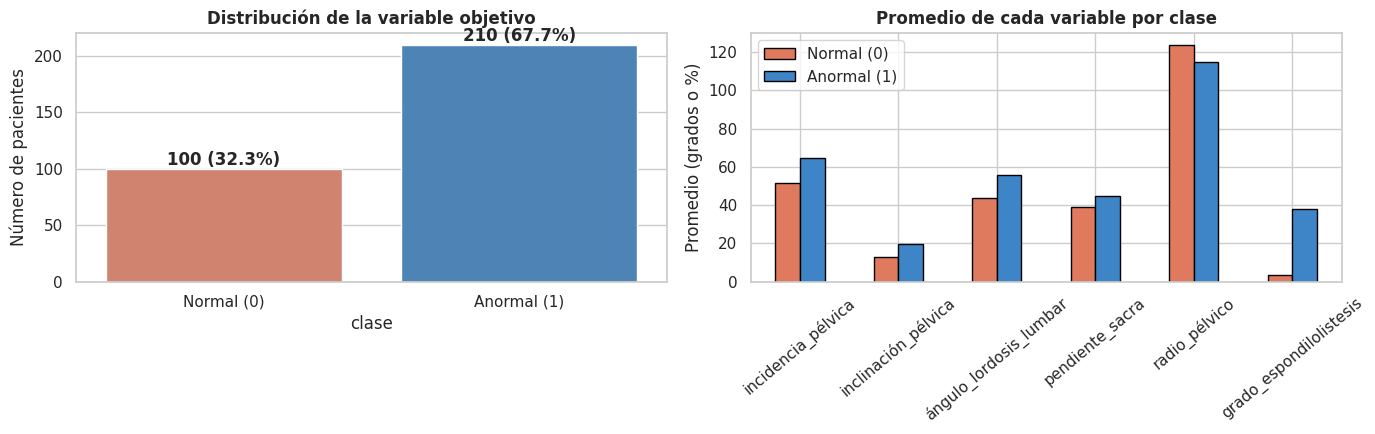

=== PROMEDIO POR CLASE ===
clase                    Normal (0)  Anormal (1)
incidencia_pélvica             51.7         64.7
inclinación_pélvica            12.8         19.8
ángulo_lordosis_lumbar         43.5         55.9
pendiente_sacra                38.9         44.9
radio_pélvico                 123.9        115.1
grado_espondilolistesis         3.3         38.1


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

conteo = df['clase'].map({0: 'Normal (0)', 1: 'Anormal (1)'}).value_counts().reindex(['Normal (0)', 'Anormal (1)'])
ax = sns.barplot(x=conteo.index, y=conteo.values, palette=['#e07a5f', '#3d85c6'], ax=axes[0])
for i, v in enumerate(conteo.values):
    ax.text(i, v + 3, f"{v} ({100*v/len(df):.1f}%)", ha='center', fontweight='bold')
axes[0].set_title('Distribución de la variable objetivo', fontweight='bold'); axes[0].set_ylabel('Número de pacientes')

medias = df.groupby('clase')[FEATURES].mean().T
medias.columns = ['Normal (0)', 'Anormal (1)']
medias.plot(kind='bar', ax=axes[1], color=['#e07a5f', '#3d85c6'], edgecolor='black')
axes[1].set_title('Promedio de cada variable por clase', fontweight='bold')
axes[1].set_ylabel('Promedio (grados o %)'); axes[1].tick_params(axis='x', rotation=40)
plt.tight_layout(); plt.show()

print("=== PROMEDIO POR CLASE ===")
print(df.groupby('clase')[FEATURES].mean().round(1).rename(index={0: 'Normal (0)', 1: 'Anormal (1)'}).T)

El gráfico de la izquierda muestra que el conjunto está desbalanceado: 210 pacientes anormales (67.7 %) frente a 100 normales (32.3 %), una proporción aproximada de 2.1 a 1. Un clasificador que predijera siempre "Anormal" alcanzaría una exactitud de 67.7 %; por ello la *accuracy* por sí sola no es suficiente y se complementa con precisión, recall, F1-Score y ROC AUC. Este desbalance justifica además el uso de SMOTE (sección 5).

El gráfico de la derecha compara los promedios por clase: casi todas las variables son mayores en la clase Anormal, con la diferencia más marcada en el grado de espondilolistesis (38.1 % frente a 3.3 %); solo el radio pélvico es menor (115.1° frente a 123.9°).

**Histogramas y diagramas de caja por clase**

Se examina la forma de la distribución de cada variable y su capacidad para separar las dos clases.

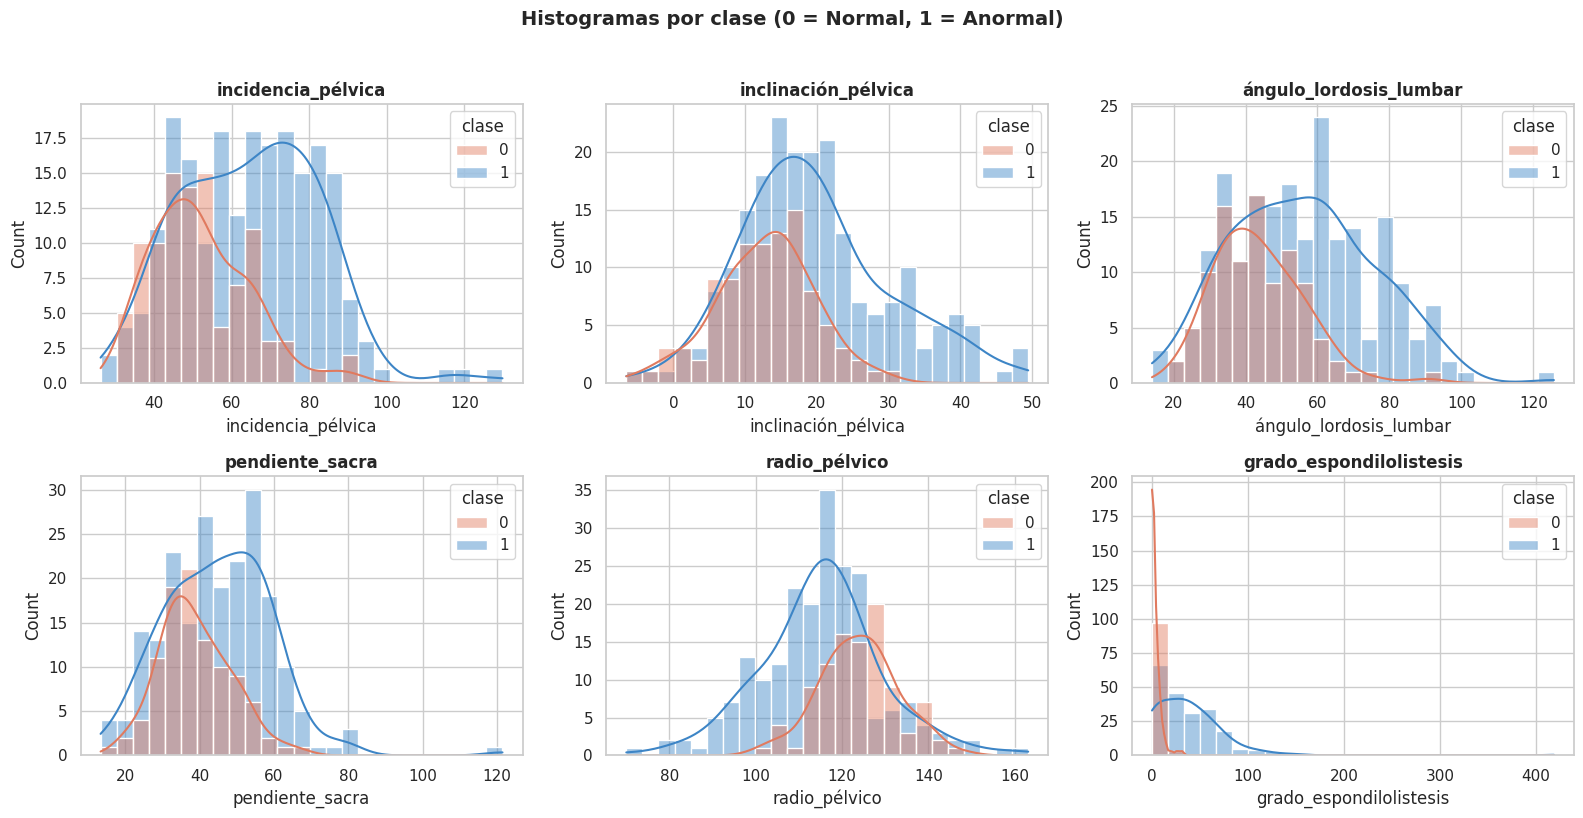

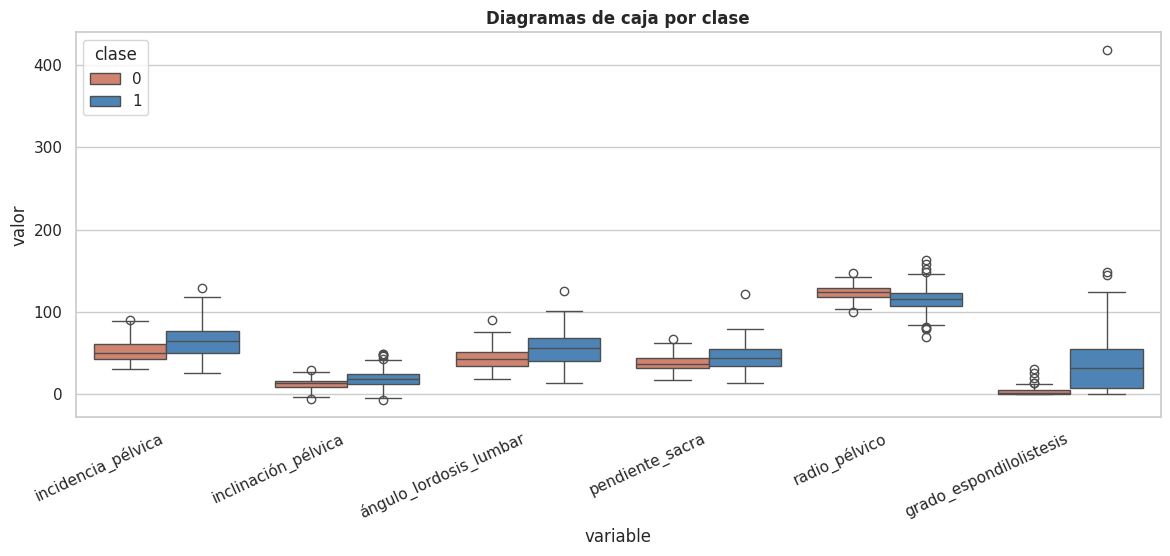

=== GRADO DE ESPONDILOLISTESIS POR CLASE ===
Normal: percentil 75 = 4.97 % | máximo = 31.17 %
Anormal: mediana = 31.95 %
Pacientes con valor > 50 %: 68 | de ellos anormales: 68
Pacientes con valor > 25 %: 136 | de ellos anormales: 134


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), FEATURES):
    sns.histplot(data=df, x=c, hue='clase', kde=True, bins=25, palette=['#e07a5f', '#3d85c6'],
                 alpha=0.45, ax=ax)
    ax.set_title(c, fontweight='bold')
plt.suptitle('Histogramas por clase (0 = Normal, 1 = Anormal)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()

plt.figure(figsize=(14, 5))
dfm = df.melt(id_vars='clase', var_name='variable', value_name='valor')
sns.boxplot(data=dfm, x='variable', y='valor', hue='clase', palette=['#e07a5f', '#3d85c6'])
plt.xticks(rotation=25, ha='right'); plt.title('Diagramas de caja por clase', fontweight='bold')
plt.show()

gs_ = df['grado_espondilolistesis']
print("=== GRADO DE ESPONDILOLISTESIS POR CLASE ===")
print(f"Normal: percentil 75 = {gs_[df.clase == 0].quantile(.75):.2f} % | máximo = {gs_[df.clase == 0].max():.2f} %")
print(f"Anormal: mediana = {gs_[df.clase == 1].median():.2f} %")
print(f"Pacientes con valor > 50 %: {int((gs_ > 50).sum())} | de ellos anormales: {int(df.loc[gs_ > 50, 'clase'].sum())}")
print(f"Pacientes con valor > 25 %: {int((gs_ > 25).sum())} | de ellos anormales: {int(df.loc[gs_ > 25, 'clase'].sum())}")

Los histogramas muestran que la variable que mejor separa las clases es el grado de espondilolistesis: en pacientes normales los valores se concentran cerca de cero (percentil 75 de 4.97 %), mientras que en pacientes anormales la distribución es mucho más dispersa (mediana de 31.95 %) y con una cola larga. De hecho, los 68 pacientes con espondilolistesis superior al 50 % son todos anormales, y de los 136 con valores superiores al 25 %, 134 son anormales. En las demás variables las dos distribuciones se traslapan considerablemente, aunque con centros desplazados.

**Diagramas de dispersión**

Se representan pares de variables clínicamente relacionadas, coloreados por clase, y un *pairplot* con todas las combinaciones.

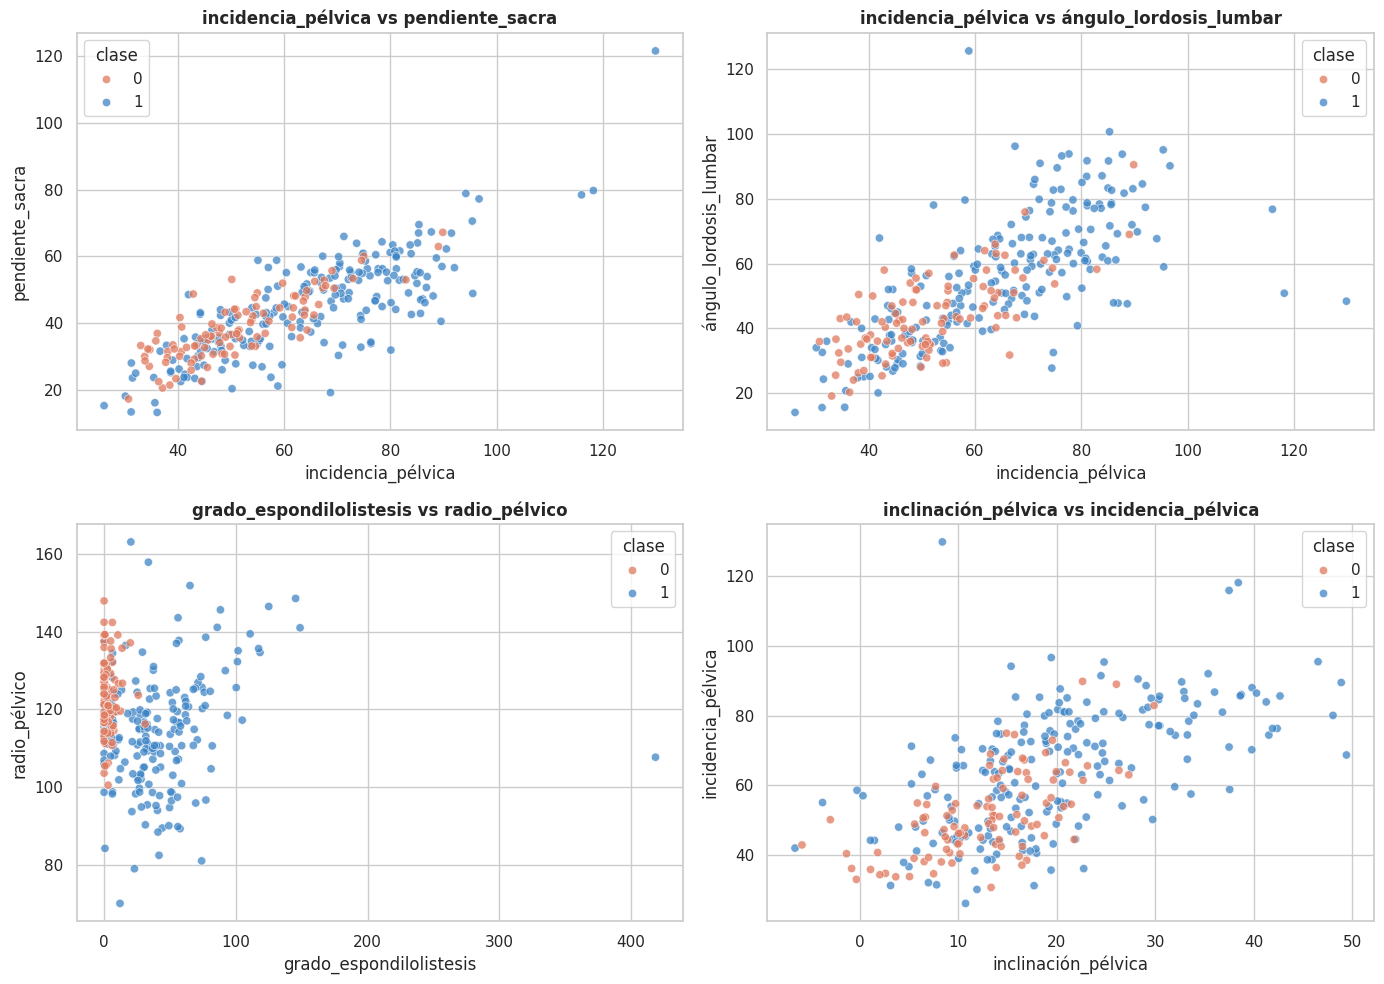

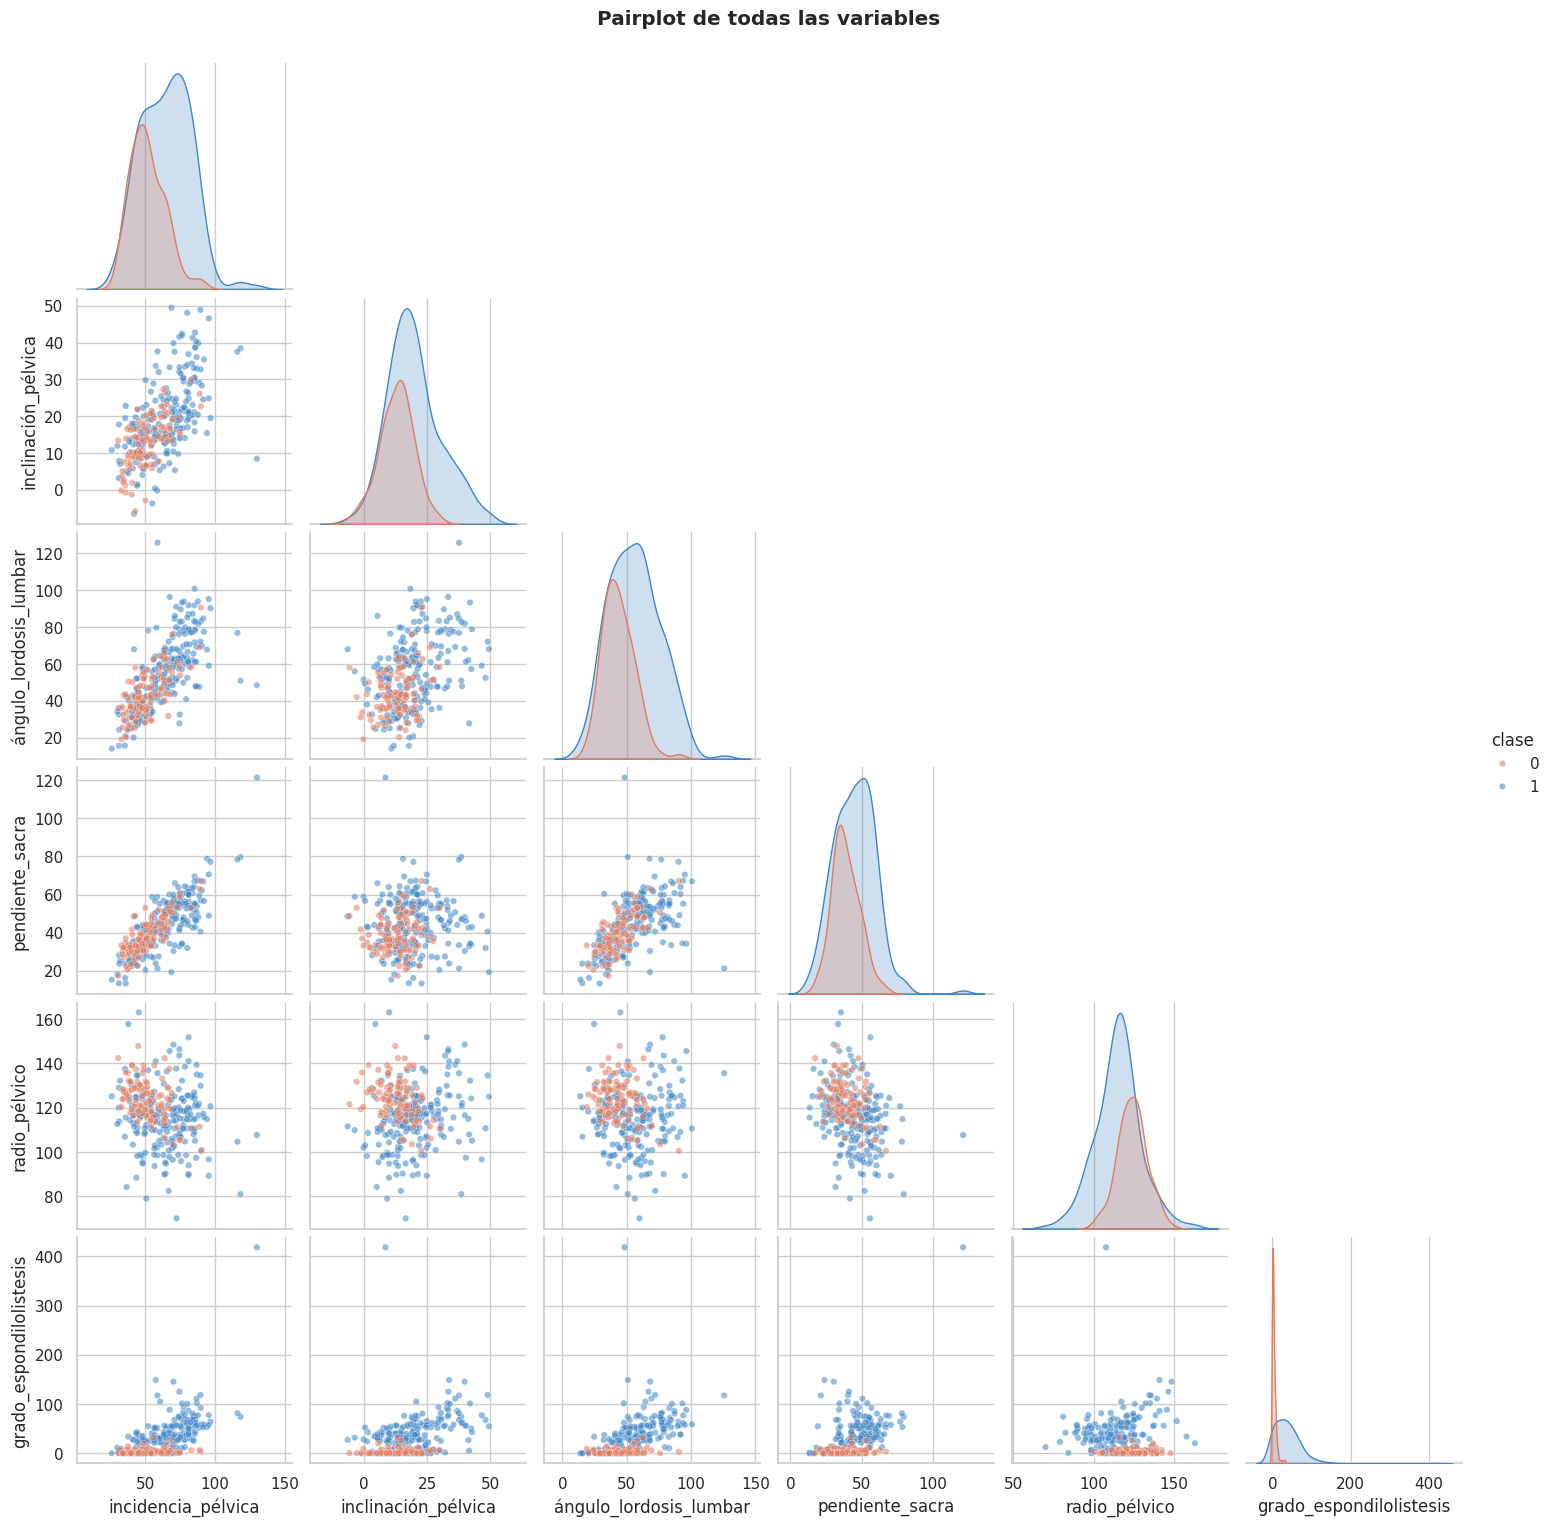

In [ ]:
pares = [('incidencia_pélvica', 'pendiente_sacra'),
         ('incidencia_pélvica', 'ángulo_lordosis_lumbar'),
         ('grado_espondilolistesis', 'radio_pélvico'),
         ('inclinación_pélvica', 'incidencia_pélvica')]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (x, y) in zip(axes.ravel(), pares):
    sns.scatterplot(data=df, x=x, y=y, hue='clase', palette=['#e07a5f', '#3d85c6'], alpha=0.75, ax=ax)
    ax.set_title(f'{x} vs {y}', fontweight='bold')
plt.tight_layout(); plt.show()

g = sns.pairplot(df, hue='clase', palette=['#e07a5f', '#3d85c6'], diag_kind='kde',
                 plot_kws={'alpha': 0.55, 's': 22}, corner=True)
g.fig.suptitle('Pairplot de todas las variables', y=1.02, fontweight='bold')
plt.show()

En el diagrama de *incidencia pélvica* frente a *pendiente sacra* se observa una relación lineal positiva muy clara, esperable porque la pendiente sacra es uno de los componentes geométricos de la incidencia. La relación entre incidencia pélvica y lordosis lumbar también es positiva y marcada. En ambos gráficos los pacientes anormales ocupan preferentemente la zona de valores altos, con una región intermedia donde las dos clases se mezclan.

En el gráfico de *espondilolistesis* frente a *radio pélvico*, los normales forman una nube compacta con espondilolistesis cercana a cero y radio pélvico alto, mientras que los anormales se extienden hacia espondilolistesis altas y radios menores. El *pairplot* refuerza que las clases no son separables linealmente con un solo par de variables, lo que justifica el uso de modelos no lineales (KNN, Random Forest y XGBoost).

### **4.4 Matriz de correlación**

La matriz de correlación de Pearson permite detectar redundancias entre variables y medir la asociación de cada una con la clase. Adicionalmente, se verifica numéricamente la relación geométrica **PI = PT + SS** entre la incidencia pélvica, la inclinación pélvica y la pendiente sacra (Topolniak et al., 2022).

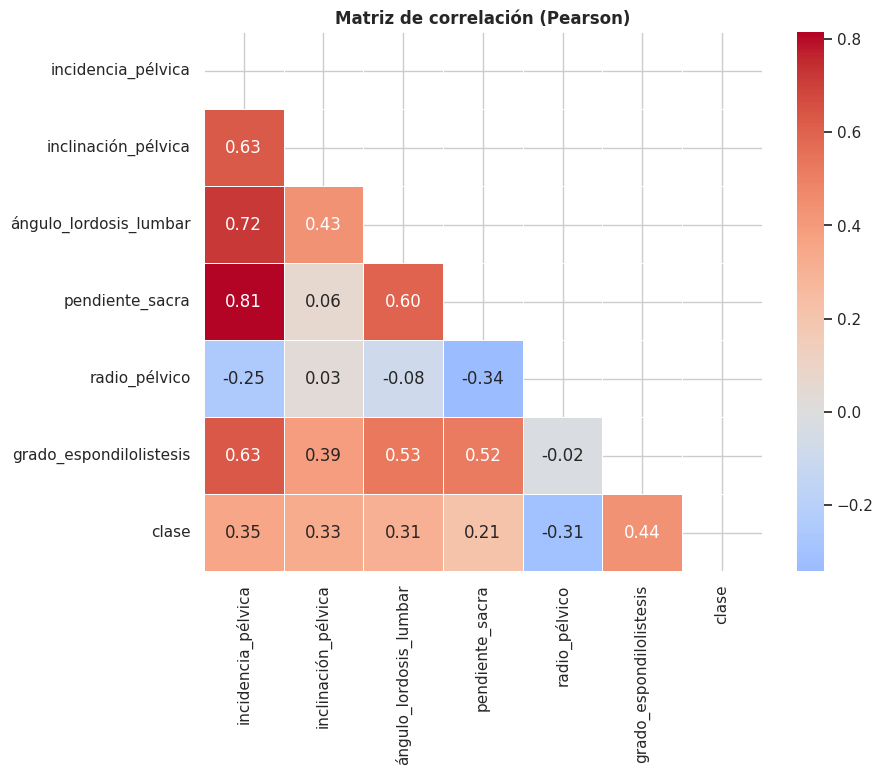

=== Pares de variables con |correlación| ≥ 0.6 ===


,level_0,level_1,corr
3,pendiente_sacra,incidencia_pélvica,0.815
1,ángulo_lordosis_lumbar,incidencia_pélvica,0.717
10,grado_espondilolistesis,incidencia_pélvica,0.634
0,inclinación_pélvica,incidencia_pélvica,0.629



=== Correlación de cada variable con la clase ===


,corr con clase
grado_espondilolistesis,0.440
incidencia_pélvica,0.353
inclinación_pélvica,0.326
ángulo_lordosis_lumbar,0.312
radio_pélvico,-0.310
pendiente_sacra,0.211



Residuo máximo |PI − (PT + SS)| = 1.00e-08


In [ ]:
corr = df.corr()
plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, mask=mask, linewidths=.5)
plt.title('Matriz de correlación (Pearson)', fontweight='bold'); plt.show()

print("=== Pares de variables con |correlación| ≥ 0.6 ===")
pares_altos = (corr.where(~mask).stack().rename('corr').reset_index()
                   .query('abs(corr) >= 0.6 and level_0 != "clase" and level_1 != "clase"')
                   .sort_values('corr', key=abs, ascending=False))
display(pares_altos.round(3))

print("\n=== Correlación de cada variable con la clase ===")
display(corr['clase'].drop('clase').sort_values(key=abs, ascending=False).round(3).to_frame('corr con clase'))

residuo = df['incidencia_pélvica'] - (df['inclinación_pélvica'] + df['pendiente_sacra'])
print(f"\nResiduo máximo |PI − (PT + SS)| = {residuo.abs().max():.2e}")

La incidencia pélvica es la variable más conectada con las demás (0.81 con la pendiente sacra, 0.72 con la lordosis lumbar y 0.63 con la inclinación pélvica y con la espondilolistesis), mientras que el radio pélvico tiene correlaciones débiles o negativas (entre −0.34 y 0.03) y aporta información en gran medida independiente. Respecto a la clase, la variable más asociada es el grado de espondilolistesis (r = 0.44) y ninguna correlación individual supera 0.5, lo que confirma que la clasificación requiere combinar varias variables.

El residuo máximo de la comprobación PI − (PT + SS) es del orden de 10⁻⁸: la identidad geométrica se cumple de forma exacta, de modo que una de las tres variables es matemáticamente redundante, lo que justifica explorar técnicas de reducción de dimensionalidad (sección 5.4).

---
## **5. Preparación de los Datos para el Entrenamiento**

### **5.1 Manejo de valores nulos**

In [ ]:
nulos = df.isnull().sum().sum()
if nulos == 0:
    print(" El conjunto de datos NO contiene valores nulos → no es necesario eliminar ni imputar registros.")
else:
    print(f" Hay {nulos} valores nulos → se imputarán con la mediana (robusta a valores atípicos).")
print("Como medida preventiva, el pipeline incluye SimpleImputer(strategy='median'), ajustado solo con datos de entrenamiento.")

 El conjunto de datos NO contiene valores nulos → no es necesario eliminar ni imputar registros.
Como medida preventiva, el pipeline incluye SimpleImputer(strategy='median'), ajustado solo con datos de entrenamiento.


No fue necesario eliminar ni imputar registros (sección 4.1); el pipeline incluye de todos modos un imputador por mediana, ajustado solo con los datos de entrenamiento, como medida preventiva ante mediciones faltantes en pacientes futuros.

### **5.2 Tratamiento de valores atípicos**

Según lo discutido en la sección 4.2, no se eliminan registros. El tratamiento se plantea en dos niveles:

1. **Corrección clínica fija:** los valores negativos de espondilolistesis se llevaron a cero (sección 3.1).
2. **Winsorización por IQR:** recorta cada variable al intervalo [Q1 − 1.5·IQR, Q3 + 1.5·IQR], calculado únicamente con el conjunto de entrenamiento de cada partición. No se eliminan filas.

### **5.3 Balanceo de clases con SMOTE**

Como se observó en el análisis gráfico, la clase Anormal representa el 67.7 % de la muestra. SMOTE genera ejemplos sintéticos de la clase minoritaria interpolando entre un ejemplo real y alguno de sus vecinos más cercanos (Chawla et al., 2002), sin limitarse a duplicar registros. Se aplica exclusivamente sobre los datos de entrenamiento y dentro del pipeline, de modo que, en la validación cruzada, cada partición de validación conserva su distribución original. Aplicar SMOTE antes de dividir los datos produciría *data leakage* y estimaciones de desempeño artificialmente optimistas, porque ejemplos sintéticos derivados de un paciente podrían quedar en el conjunto de prueba.

### **5.4 Selección de características y reducción de dimensionalidad**

Se exploran dos técnicas: el umbral de varianza (*VarianceThreshold*), que descarta variables casi constantes, y el Análisis de Componentes Principales (PCA), que proyecta los datos en nuevas variables no correlacionadas ordenadas por la varianza que explican (Jolliffe & Cadima, 2016). En esta sección el análisis es exploratorio; la selección efectiva se realiza dentro del pipeline.

,varianza (escala original),varianza (escala MinMax 0-1)
incidencia_pélvica,297.10,0.0275
inclinación_pélvica,100.17,0.0319
ángulo_lordosis_lumbar,344.25,0.0275
pendiente_sacra,180.18,0.0154
radio_pélvico,177.35,0.0204
grado_espondilolistesis,1375.71,0.0078


Con umbral 0.01 en escala MinMax se conservarían: ['incidencia_pélvica', 'inclinación_pélvica', 'ángulo_lordosis_lumbar', 'pendiente_sacra', 'radio_pélvico']


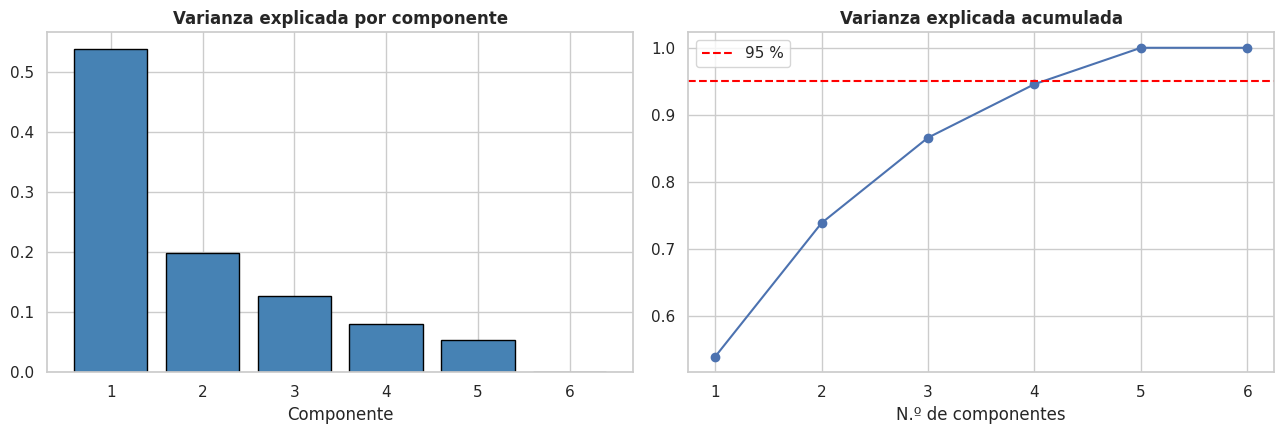

Varianza explicada por componente (%): [53.97 19.93 12.72  7.97  5.42  0.  ]
Varianza acumulada (%): [ 53.97  73.89  86.61  94.58 100.   100.  ]
Componentes necesarios para ≥ 95 %: 5


In [ ]:
X_all = df[FEATURES]

# Varianza: escala original y escala MinMax (0-1)
var_orig = X_all.var()
var_mm   = pd.Series(MinMaxScaler().fit_transform(X_all).var(axis=0), index=FEATURES)
display(pd.DataFrame({'varianza (escala original)': var_orig.round(2), 'varianza (escala MinMax 0-1)': var_mm.round(4)}))
vt = VarianceThreshold(threshold=0.01).fit(MinMaxScaler().fit_transform(X_all))
print("Con umbral 0.01 en escala MinMax se conservarían:", [f for f, k in zip(FEATURES, vt.get_support()) if k])

# PCA
pca = PCA().fit(StandardScaler().fit_transform(X_all))
cum = np.cumsum(pca.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(range(1, len(cum)+1), pca.explained_variance_ratio_, color='steelblue', edgecolor='black')
ax[0].set_title('Varianza explicada por componente', fontweight='bold'); ax[0].set_xlabel('Componente')
ax[1].plot(range(1, len(cum)+1), cum, marker='o'); ax[1].axhline(0.95, color='red', ls='--', label='95 %')
ax[1].set_title('Varianza explicada acumulada', fontweight='bold'); ax[1].set_xlabel('N.º de componentes'); ax[1].legend()
plt.tight_layout(); plt.show()
print("Varianza explicada por componente (%):", np.round(100*pca.explained_variance_ratio_, 2))
print("Varianza acumulada (%):", np.round(100*cum, 2))
print("Componentes necesarios para ≥ 95 %:", int(np.argmax(cum >= 0.95) + 1))

En escala original, la variable con mayor varianza es el grado de espondilolistesis (1375.71) y las demás oscilan entre 100.17 y 344.25. Al reescalar a 0–1, su varianza resulta la menor (≈ 0.0078) y un umbral de 0.01 la eliminaría. Esto es engañoso: el valor extremo de 418.5 % fija el máximo del rango y comprime el resto de los datos. Como es la variable más asociada con la clase, no es adecuado descartarla por varianza; por ello, dentro del pipeline el filtro de varianza usa umbral 0 (elimina solo variables constantes) y la reducción se delega a SelectKBest y PCA, evaluados con validación cruzada.

El primer componente del PCA explica el 54.0 % de la varianza y los dos primeros el 73.9 %. Se requieren cinco componentes para superar el 95 % (con cuatro se llega al 94.6 %), y el sexto explica una varianza prácticamente nula (≈ 0 %), evidencia de la dependencia lineal exacta PI = PT + SS de la sección 4.4: el espacio de seis variables tiene en realidad rango cinco. La reducción a cuatro componentes es un compromiso razonable entre simplicidad y conservación de la información.

---
## **6. Partición de los Datos**

Se divide el conjunto en 80 % para entrenamiento (248 pacientes) y 20 % para prueba (62 pacientes), con muestreo estratificado para conservar la proporción de clases en ambos subconjuntos, y con una semilla aleatoria fija (`random_state = 42`) para que la partición sea reproducible. No se reserva un conjunto de validación fijo: la validación cruzada estratificada de 5 particiones aplicada sobre el conjunto de entrenamiento cumple ese papel con mayor estabilidad, dado el tamaño reducido de la muestra. El conjunto de prueba permanece intacto hasta la evaluación final.

Entrenamiento: (248, 6) | Prueba: (62, 6)

Proporción de clases:
       Total  Train   Test
clase                     
1      0.677  0.677  0.677
0      0.323  0.323  0.323


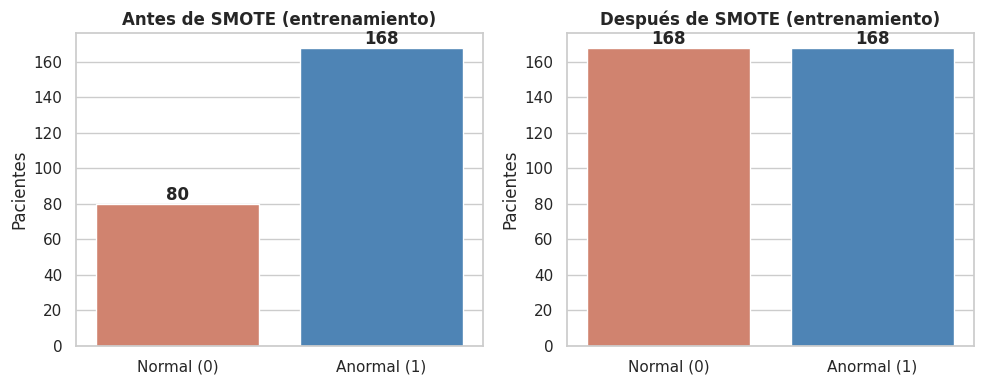

In [ ]:
X = df[FEATURES]
y = df['clase']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE,
                                                    random_state=RANDOM_STATE, stratify=y)
print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}")
print("\nProporción de clases:")
print(pd.DataFrame({'Total': y.value_counts(normalize=True), 'Train': y_train.value_counts(normalize=True),
                    'Test': y_test.value_counts(normalize=True)}).round(3))

# Demostración del efecto de SMOTE (solo sobre el conjunto de entrenamiento)
Xs = StandardScaler().fit_transform(X_train)
Xs_sm, ys_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(Xs, y_train)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (titulo, yy) in zip(ax, [('Antes de SMOTE (entrenamiento)', y_train), ('Después de SMOTE (entrenamiento)', ys_sm)]):
    c = pd.Series(yy).value_counts().sort_index()
    sns.barplot(x=['Normal (0)', 'Anormal (1)'], y=c.values, palette=['#e07a5f', '#3d85c6'], ax=a)
    for i, v in enumerate(c.values): a.text(i, v + 2, str(v), ha='center', fontweight='bold')
    a.set_title(titulo, fontweight='bold'); a.set_ylabel('Pacientes')
plt.tight_layout(); plt.show()

La partición estratificada conserva la proporción de clases (67.7 % Anormal) en entrenamiento (248 pacientes) y prueba (62 pacientes: 42 anormales y 20 normales). En el gráfico, SMOTE lleva la clase Normal de 80 a 168 pacientes, igualando a la clase Anormal (proporción 1:1). Esta demostración es solo ilustrativa; en el pipeline el balanceo se repite dentro de cada partición de la validación cruzada.

---
## **7. Definición de los Modelos y del Pipeline de Trabajo**

Se implementó un único *pipeline* para los tres modelos, encapsulado con `imblearn.pipeline.Pipeline` (que, a diferencia del `Pipeline` de scikit-learn, admite pasos de remuestreo como SMOTE). Todos los pasos se ajustan exclusivamente con los datos de entrenamiento de cada partición:

1. **Imputación** de valores nulos (mediana).
2. **Winsorización por IQR** (activable/desactivable según el experimento descrito más abajo).
3. **VarianceThreshold** (elimina variables constantes).
4. **StandardScaler** (normalización a media 0 y desviación estándar 1).
5. **SMOTE** (balanceo de clases, solo en entrenamiento).
6. **Reducción de dimensionalidad** (sin reducción, SelectKBest con k = 4 o PCA con 4 componentes; se elige con GridSearchCV).
7. **Modelo de clasificación:** KNN (Cover & Hart, 1967), Random Forest (Breiman, 2001) o XGBoost (Chen & Guestrin, 2016).

Se utilizan las bibliotecas scikit-learn (Pedregosa et al., 2011), imbalanced-learn (Lemaître et al., 2017) y XGBoost.

In [ ]:
class IQRCapper(BaseEstimator, TransformerMixin):
    # Recorta (winsoriza) cada variable a [Q1 - f*IQR, Q3 + f*IQR] calculado SOLO con los datos de entrenamiento.
    def __init__(self, factor=1.5, active=True):
        self.factor = factor
        self.active = active
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        q1, q3 = np.percentile(X, [25, 75], axis=0)
        iqr = q3 - q1
        self.lower_, self.upper_ = q1 - self.factor*iqr, q3 + self.factor*iqr
        return self
    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_, self.upper_) if self.active else X

def build_pipeline(clf, capping=False):
    return ImbPipeline([
        ('imputer',  SimpleImputer(strategy='median')),
        ('capper',   IQRCapper(active=capping)),
        ('variance', VarianceThreshold(threshold=0.0)),
        ('scaler',   StandardScaler()),
        ('smote',    SMOTE(random_state=RANDOM_STATE)),
        ('reduce',   'passthrough'),
        ('clf',      clf)
    ])

# Opciones de reducción de dimensionalidad que explorará el GridSearch
REDUCERS = ['passthrough',
            SelectKBest(score_func=f_classif, k=4),
            PCA(n_components=4, random_state=RANDOM_STATE)]

def desc_reductor(r):
    if isinstance(r, str):          return "sin reducción (6 variables originales)"
    if isinstance(r, SelectKBest):  return f"selección univariada SelectKBest (k = {r.k})"
    if isinstance(r, PCA):          return f"PCA ({r.n_components} componentes principales)"
    return str(r)
print("Pipeline definido")

Pipeline definido


Para decidir con criterio empírico si la winsorización resulta conveniente, se comparó el desempeño (validación cruzada de 5 particiones sobre el conjunto de entrenamiento) de los tres modelos con hiperparámetros base, con y sin recorte de atípicos. La winsorización se adopta únicamente si mejora el F1 promedio en más de 0.005, un margen mínimo fijado a priori para no modificar los datos por diferencias que podrían deberse al azar.

In [ ]:
modelos_ref = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE)
}
filas = []
for nombre, clf in modelos_ref.items():
    for cap in [False, True]:
        r = cross_validate(build_pipeline(clf, cap), X_train, y_train, cv=CV,
                           scoring=['recall', 'f1'], n_jobs=-1)
        filas.append({'Modelo': nombre, 'Winsorización': 'Sí' if cap else 'No',
                      'Recall CV': r['test_recall'].mean(), 'F1 CV': r['test_f1'].mean()})
cmp_out = pd.DataFrame(filas)
display(cmp_out.round(4))

f1_sin = cmp_out.query("Winsorización == 'No'")['F1 CV'].mean()
f1_con = cmp_out.query("Winsorización == 'Sí'")['F1 CV'].mean()
USAR_CAPPING = bool(f1_con > f1_sin + 0.005)

print(f"\nF1 promedio de los tres modelos → sin winsorización: {f1_sin:.4f} | con winsorización: {f1_con:.4f} | diferencia: {f1_con - f1_sin:+.4f}")
print(f"¿Se aplica la winsorización? (requiere una mejora mayor a 0.005): {USAR_CAPPING}")

,Modelo,Winsorización,Recall CV,F1 CV
0,KNN,No,0.7497,0.8096
1,KNN,Sí,0.7738,0.8279
2,Random Forest,No,0.8273,0.8579
3,Random Forest,Sí,0.8214,0.8523
4,XGBoost,No,0.8207,0.8486
5,XGBoost,Sí,0.8207,0.8455



F1 promedio de los tres modelos → sin winsorización: 0.8387 | con winsorización: 0.8419 | diferencia: +0.0032
¿Se aplica la winsorización? (requiere una mejora mayor a 0.005): False


Según la tabla, el F1 de KNN mejora al winsorizar (de 0.8096 a 0.8279), mientras que el de Random Forest (de 0.8579 a 0.8523) y el de XGBoost (de 0.8486 a 0.8455) no mejora. La impresión inferior muestra el F1 promedio de los tres modelos (0.8387 sin winsorización y 0.8419 con ella, diferencia de +0.0032) frente al margen mínimo de 0.005 fijado de antemano. Como no se supera el margen, no se aplica la winsorización y se conservan los valores atípicos, por su naturaleza clínica (sección 4.2). Solo KNN, el único modelo basado en distancias, muestra una mejora individual.

---
## **8. Ajuste de Hiperparámetros con GridSearchCV**

Para cada modelo se definió una cuadrícula de hiperparámetros, incluyendo además la técnica de reducción de dimensionalidad como un hiperparámetro más del pipeline. La búsqueda se realizó con GridSearchCV y validación cruzada estratificada de 5 particiones, evaluando simultáneamente accuracy, precisión, recall, F1 y ROC AUC.

| Modelo | Hiperparámetros explorados |
|---|---|
| **KNN** | número de vecinos (3, 5, 7, 9, 11, 15), ponderación (uniforme o por distancia), métrica de distancia (Manhattan o Euclídea) y técnica de reducción |
| **Random Forest** | número de árboles (100, 300), profundidad máxima (sin límite, 5, 10), mínimo de muestras por hoja (1, 2, 4) y técnica de reducción |
| **XGBoost** | número de estimadores (100, 200), tasa de aprendizaje (0.01, 0.05, 0.1), profundidad máxima (3, 5), submuestreo (0.8, 1.0) y técnica de reducción |

La combinación ganadora se elige según el F1-Score, que equilibra sensibilidad y precisión. Se descartó optimizar únicamente el recall porque esa métrica se maximiza trivialmente clasificando a todos los pacientes como anormales, lo que no es útil clínicamente. Puede cambiarse con la variable `REFIT` en la celda de configuración.

In [ ]:
grids = {
    'KNN': (KNeighborsClassifier(), {
        'reduce': REDUCERS,
        'clf__n_neighbors': [3, 5, 7, 9, 11, 15],
        'clf__weights': ['uniform', 'distance'],
        'clf__p': [1, 2]}),
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), {
        'reduce': REDUCERS,
        'clf__n_estimators': [100, 300],
        'clf__max_depth': [None, 5, 10],
        'clf__min_samples_leaf': [1, 2, 4]}),
    'XGBoost': (XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=1), {
        'reduce': REDUCERS,
        'clf__n_estimators': [100, 200],
        'clf__learning_rate': [0.01, 0.05, 0.1],
        'clf__max_depth': [3, 5],
        'clf__subsample': [0.8, 1.0]})
}

busquedas = {}
for nombre, (clf, grid) in grids.items():
    gs = GridSearchCV(build_pipeline(clf, USAR_CAPPING), grid, cv=CV, scoring=SCORING,
                      refit=REFIT, n_jobs=-1)
    gs.fit(X_train, y_train)
    busquedas[nombre] = gs
    print(f" {nombre}: {len(gs.cv_results_['params'])} combinaciones evaluadas | mejor {REFIT} en CV = {gs.best_score_:.4f}")

filas = []
for nombre, gs in busquedas.items():
    hp = {k.replace('clf__', ''): v for k, v in gs.best_params_.items() if k.startswith('clf__')}
    filas.append({'Modelo': nombre, 'Reducción elegida': desc_reductor(gs.best_params_['reduce']),
                  'Hiperparámetros óptimos': str(hp), 'Combinaciones': len(gs.cv_results_['params']),
                  f'{REFIT.upper()} en CV': round(gs.best_score_, 4)})
tabla_mejores = pd.DataFrame(filas)
pd.set_option('display.max_colwidth', None)   # mostrar completos los hiperparámetros
display(tabla_mejores)
for _nom, _gs in busquedas.items():
    print(f"{_nom}: {_gs.best_params_}")

 KNN: 72 combinaciones evaluadas | mejor f1 en CV = 0.8464
 Random Forest: 54 combinaciones evaluadas | mejor f1 en CV = 0.8700
 XGBoost: 72 combinaciones evaluadas | mejor f1 en CV = 0.8745


,Modelo,Reducción elegida,Hiperparámetros óptimos,Combinaciones,F1 en CV
0,KNN,selección univariada SelectKBest (k = 4),"{'n_neighbors': 3, 'p': 2, 'weights': 'distance'}",72,0.8464
1,Random Forest,PCA (4 componentes principales),"{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 300}",54,0.8700
2,XGBoost,selección univariada SelectKBest (k = 4),"{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}",72,0.8745


KNN: {'clf__n_neighbors': 3, 'clf__p': 2, 'clf__weights': 'distance', 'reduce': SelectKBest(k=4)}
Random Forest: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 300, 'reduce': PCA(n_components=4, random_state=42)}
XGBoost: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 100, 'clf__subsample': 1.0, 'reduce': SelectKBest(k=4)}


XGBoost obtuvo el mayor F1 en validación cruzada (0.8745), seguido de Random Forest (0.8700) y KNN (0.8464). Las mejores combinaciones fueron: KNN con 3 vecinos, ponderación por distancia y distancia euclídea; Random Forest con 300 árboles, profundidad máxima de 10 y 1 muestra mínima por hoja; y XGBoost con 100 estimadores, tasa de aprendizaje de 0.1, profundidad de 5 y submuestreo de 1.0. Ningún modelo eligió trabajar con las seis variables originales: dos eligieron SelectKBest (k = 4) y uno PCA (4 componentes), es decir, reducir a cuatro dimensiones no perjudicó el desempeño. Varios óptimos quedaron en el borde de la cuadrícula (3 vecinos, 1 muestra por hoja, tasa de aprendizaje de 0.1 y profundidad de 5), por lo que una búsqueda más amplia podría mejorarlos ligeramente.

---
## **9. Validación Cruzada y Validación Out-of-Bag**

### **9.1 Validación cruzada**

La validación cruzada estratificada de 5 particiones estima la capacidad de generalización de cada modelo: en cada iteración se entrena con cuatro quintos de los datos de entrenamiento (aplicando todo el pipeline, incluido SMOTE) y se valida con el quinto restante, que conserva su distribución original. Se reporta la media y la desviación estándar de cada métrica para la mejor combinación de hiperparámetros de cada modelo; una desviación pequeña indica un desempeño estable.

In [ ]:
def resumen_cv(gs):
    i = gs.best_index_
    return {m: (gs.cv_results_[f'mean_test_{m}'][i], gs.cv_results_[f'std_test_{m}'][i]) for m in SCORING}

nombres_m = {'accuracy': 'Accuracy', 'precision': 'Precisión', 'recall': 'Recall', 'f1': 'F1-Score', 'roc_auc': 'ROC AUC', 'f2': 'F2-Score'}
tabla_cv = pd.DataFrame({n: {nombres_m[m]: f"{v[0]:.3f} ± {v[1]:.3f}" for m, v in resumen_cv(gs).items()}
                         for n, gs in busquedas.items()}).T
print("=== VALIDACIÓN CRUZADA 5-FOLD (media ± desviación estándar, mejor combinación de cada modelo) ===")
display(tabla_cv)

=== VALIDACIÓN CRUZADA 5-FOLD (media ± desviación estándar, mejor combinación de cada modelo) ===


,Accuracy,Precisión,Recall,F1-Score,ROC AUC,F2-Score
KNN,0.802 ± 0.055,0.891 ± 0.049,0.809 ± 0.067,0.846 ± 0.045,0.832 ± 0.089,0.823 ± 0.057
Random Forest,0.826 ± 0.046,0.886 ± 0.048,0.857 ± 0.044,0.870 ± 0.034,0.886 ± 0.056,0.862 ± 0.037
XGBoost,0.834 ± 0.080,0.898 ± 0.071,0.857 ± 0.076,0.875 ± 0.061,0.903 ± 0.059,0.863 ± 0.068


XGBoost obtuvo el mayor F1 medio (0.875) y ROC AUC (0.903), y Random Forest fue el más estable (desviación estándar del F1 de 0.034 frente a 0.061 de XGBoost); KNN fue el más bajo en F1, recall, accuracy y ROC AUC. Con 248 pacientes, desviaciones de entre 0.034 y 0.061 indican que las diferencias pequeñas entre modelos deben interpretarse con cautela. Además, estas cifras provienen de la misma validación con la que se eligió la mejor combinación entre decenas de candidatas, por lo que tienden a ser optimistas; la sección 9.2 las contrasta con particiones nuevas.

### **9.2 Validación cruzada repetida**

Con 248 pacientes de entrenamiento, una sola validación de 5 particiones depende del reparto aleatorio. Para medir la estabilidad se repite 3 veces con particiones distintas (`RepeatedStratifiedKFold`, 15 evaluaciones por modelo) y una semilla diferente a la del ajuste, sobre la mejor combinación de cada modelo. Las evaluaciones comparten pacientes, por lo que la desviación estándar es una referencia de variabilidad y no una medida estadística exacta.

=== VALIDACIÓN CRUZADA REPETIDA (5 particiones × 3 repeticiones; media ± desviación estándar) ===


,Accuracy,Precisión,Recall,F1-Score,ROC AUC,F2-Score
Modelo,,,,,,
KNN,0.776 ± 0.055,0.879 ± 0.036,0.776 ± 0.066,0.823 ± 0.047,0.826 ± 0.051,0.794 ± 0.059
Random Forest,0.819 ± 0.054,0.883 ± 0.033,0.846 ± 0.075,0.862 ± 0.045,0.882 ± 0.065,0.852 ± 0.062
XGBoost,0.781 ± 0.049,0.876 ± 0.030,0.790 ± 0.084,0.828 ± 0.046,0.872 ± 0.035,0.804 ± 0.069


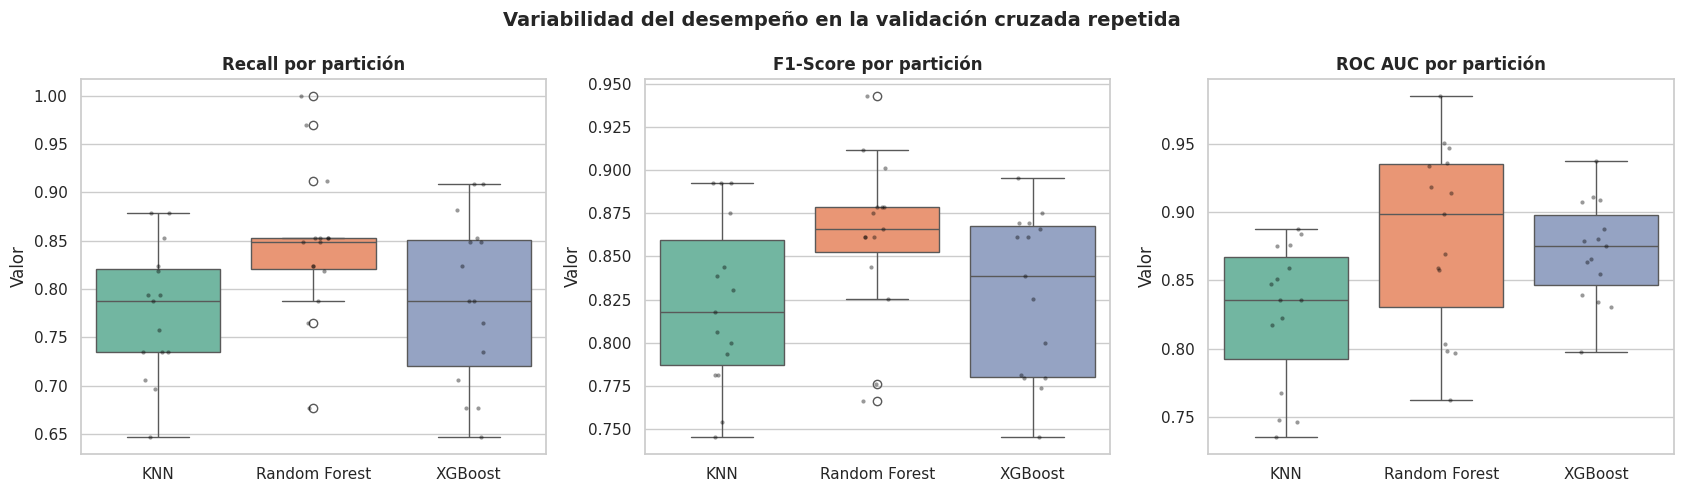


Diferencia entre el mayor y el menor F1 medio: 0.039 | menor desviación estándar del F1: 0.045


In [ ]:
CV_REP = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)   # semilla distinta a la del ajuste

resultados_rep, filas_res, filas_long = {}, [], []
for n, gs in busquedas.items():
    r = cross_validate(gs.best_estimator_, X_train, y_train, cv=CV_REP, scoring=SCORING, n_jobs=-1)
    resultados_rep[n] = {m: (r[f'test_{m}'].mean(), r[f'test_{m}'].std()) for m in SCORING}
    fila = {'Modelo': n}
    for m in SCORING:
        vals = r[f'test_{m}']
        fila[nombres_m[m]] = f"{vals.mean():.3f} ± {vals.std():.3f}"
        filas_long += [{'Modelo': n, 'Métrica': nombres_m[m], 'Valor': v} for v in vals]
    filas_res.append(fila)

print("=== VALIDACIÓN CRUZADA REPETIDA (5 particiones × 3 repeticiones; media ± desviación estándar) ===")
display(pd.DataFrame(filas_res).set_index('Modelo'))

df_long = pd.DataFrame(filas_long)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, met in zip(axes, ['Recall', 'F1-Score', 'ROC AUC']):
    sub = df_long[df_long['Métrica'] == met]
    sns.boxplot(data=sub, x='Modelo', y='Valor', palette='Set2', ax=ax)
    sns.stripplot(data=sub, x='Modelo', y='Valor', color='black', alpha=0.4, size=3, ax=ax)
    ax.set_title(f'{met} por partición', fontweight='bold'); ax.set_xlabel('')
plt.suptitle('Variabilidad del desempeño en la validación cruzada repetida', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

f1_medias = [v['f1'][0] for v in resultados_rep.values()]
print(f"\nDiferencia entre el mayor y el menor F1 medio: {max(f1_medias) - min(f1_medias):.3f} | menor desviación estándar del F1: {min(v['f1'][1] for v in resultados_rep.values()):.3f}")

Random Forest obtuvo el mayor recall (0.846), F1 (0.862) y ROC AUC (0.882) medios, frente a recall de 0.776 en KNN y 0.790 en XGBoost, con desviaciones del F1 similares en los tres modelos (0.045 a 0.047). Los F1 medios (0.823, 0.862 y 0.828) están separados por menos de lo que varía cada uno entre particiones (la impresión inferior muestra una diferencia de 0.039 entre el mayor y el menor, frente a una desviación mínima de 0.045), por lo que las diferencias entre modelos no son concluyentes. Los valores son menores que en la validación simple de la sección 9.1 en XGBoost (F1 de 0.875 a 0.828) y KNN (de 0.846 a 0.823) y casi iguales en Random Forest (de 0.870 a 0.862); esto es coherente con el optimismo de elegir los hiperparámetros con la misma validación con que se reporta el resultado (Cawley & Talbot, 2010). El recall es la métrica con mayor desviación estándar en los tres modelos.

### **9.3 Validación Out-of-Bag (OOB) del Random Forest**

Cada árbol se entrena con una muestra *bootstrap* y alrededor del 37 % de los pacientes queda fuera; esos pacientes (*out-of-bag*) permiten evaluar el modelo sin un conjunto de validación separado (Breiman, 2001). Como el pipeline completo no expone el puntaje OOB, se reproducen sus pasos previos con los mejores hiperparámetros y se analizan dos escenarios:

- **A. Con SMOTE:** el bosque se entrena con datos balanceados; el OOB tiende a ser optimista, porque un paciente sintético es una interpolación de reales y parte de lo evaluado es sintético.
- **B. Sin SMOTE y con `class_weight='balanced_subsample'`:** solo evalúa pacientes reales y es una estimación más honesta.

Se grafica el error OOB según el número de árboles.

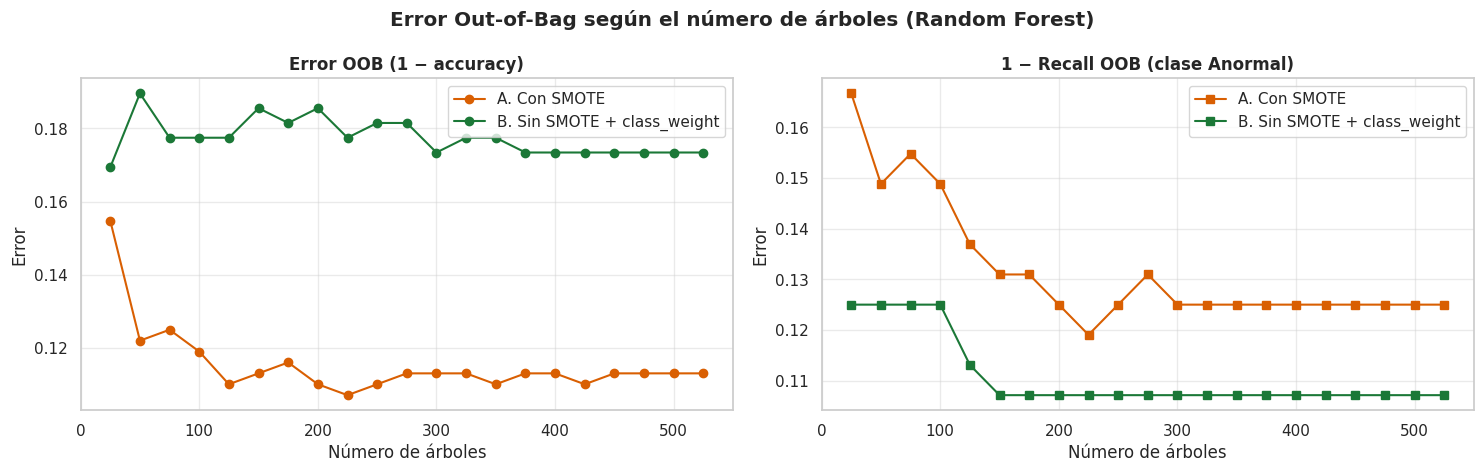

,Pacientes evaluados (OOB),Accuracy OOB,Recall OOB (Anormal)
Escenario,,,
A. Con SMOTE,336,0.8869,0.8750
B. Sin SMOTE + class_weight,248,0.8266,0.8929
Validación cruzada 5-fold (referencia),248,0.8264,0.8570


In [ ]:
def preparar_entrenamiento(pipe_ajustado, X, y_, usar_smote=True):
    """Reaplica manualmente los pasos previos al clasificador (clonados y reajustados con X, y_)."""
    Xt, yt = np.asarray(X, dtype=float).copy(), np.asarray(y_)
    for nombre_paso, paso in pipe_ajustado.steps[:-1]:
        if nombre_paso == 'smote':
            if usar_smote:
                Xt, yt = clone(paso).fit_resample(Xt, yt)
            continue
        if isinstance(paso, str):          # 'passthrough'
            continue
        Xt = clone(paso).fit_transform(Xt, yt)
    return Xt, yt

def metricas_oob(rf, y_):
    p = rf.oob_decision_function_
    ok = ~np.isnan(p).any(axis=1)             # pacientes que quedaron fuera de al menos un árbol
    pred = (p[ok, 1] >= 0.5).astype(int)
    return accuracy_score(y_[ok], pred), recall_score(y_[ok], pred), int(ok.sum())

gs_rf = busquedas['Random Forest']
best_rf = gs_rf.best_estimator_
bp = {k.replace('clf__', ''): v for k, v in gs_rf.best_params_.items() if k.startswith('clf__')}
n_best = bp.pop('n_estimators')

ESC = {'A. Con SMOTE': dict(smote=True, cw=None),
       'B. Sin SMOTE + class_weight': dict(smote=False, cw='balanced_subsample')}
datos_oob = {k: preparar_entrenamiento(best_rf, X_train, y_train, v['smote']) for k, v in ESC.items()}

arboles = list(range(25, 526, 25))
curvas = {k: {'acc': [], 'rec': []} for k in ESC}
for k, v in ESC.items():
    Xo, yo = datos_oob[k]
    for n in arboles:
        rf = RandomForestClassifier(n_estimators=n, oob_score=True, bootstrap=True, class_weight=v['cw'],
                                    random_state=RANDOM_STATE, n_jobs=-1, **bp).fit(Xo, yo)
        a, r_, _ = metricas_oob(rf, yo)
        curvas[k]['acc'].append(a); curvas[k]['rec'].append(r_)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for k, c in zip(ESC, ['#d95f02', '#1b7837']):
    axes[0].plot(arboles, 1 - np.array(curvas[k]['acc']), marker='o', color=c, label=k)
    axes[1].plot(arboles, 1 - np.array(curvas[k]['rec']), marker='s', color=c, label=k)
axes[0].set_title('Error OOB (1 − accuracy)', fontweight='bold'); axes[1].set_title('1 − Recall OOB (clase Anormal)', fontweight='bold')
for ax in axes: ax.set_xlabel('Número de árboles'); ax.set_ylabel('Error'); ax.grid(alpha=.4); ax.legend()
plt.suptitle('Error Out-of-Bag según el número de árboles (Random Forest)', fontweight='bold'); plt.tight_layout(); plt.show()

# Resultado con el número de árboles óptimo del GridSearch, comparado con la validación cruzada
i_cv = gs_rf.best_index_
acc_cv_rf = gs_rf.cv_results_['mean_test_accuracy'][i_cv]; rec_cv_rf = gs_rf.cv_results_['mean_test_recall'][i_cv]
oob_resumen, filas = {}, []
for k, v in ESC.items():
    Xo, yo = datos_oob[k]
    rf = RandomForestClassifier(n_estimators=n_best, oob_score=True, bootstrap=True, class_weight=v['cw'],
                                random_state=RANDOM_STATE, n_jobs=-1, **bp).fit(Xo, yo)
    a, r_, nv = metricas_oob(rf, yo)
    oob_resumen[k] = {'acc': a, 'rec': r_, 'n': len(yo)}
    filas.append({'Escenario': k, 'Pacientes evaluados (OOB)': nv, 'Accuracy OOB': round(a, 4), 'Recall OOB (Anormal)': round(r_, 4)})
filas.append({'Escenario': 'Validación cruzada 5-fold (referencia)', 'Pacientes evaluados (OOB)': len(y_train),
              'Accuracy OOB': round(acc_cv_rf, 4), 'Recall OOB (Anormal)': round(rec_cv_rf, 4)})
display(pd.DataFrame(filas).set_index('Escenario'))

En el escenario B (sin SMOTE y con ponderación de clases, el más fiable porque solo evalúa pacientes reales), la curva del error OOB oscila entre aproximadamente 0.17 y 0.19 con pocos árboles y se mantiene estable en torno a 0.17 desde cerca de 375 árboles. Con el número de árboles óptimo (300), la tabla muestra una exactitud OOB de 0.8266 y un recall de 0.8929, frente a 0.8264 y 0.8570 en la validación cruzada: las exactitudes prácticamente coinciden, lo que respalda que la estimación no depende del método de validación.

El escenario A (con SMOTE) muestra una exactitud OOB mayor (0.8869, error en torno a 0.11), pero se evalúa sobre 336 observaciones balanceadas que incluyen ejemplos sintéticos, mientras que B se evalúa sobre 248 pacientes reales; además, su recall (0.8750) no supera al de B (0.8929). Por ello, el OOB con SMOTE no debe usarse como única evidencia del desempeño.

---
## **10. Normalización de los Datos**

Los algoritmos basados en distancias, como KNN, quedan dominados por las variables de mayor magnitud si las escalas son muy distintas. Por ello el pipeline incluye `StandardScaler` (media 0 y desviación estándar 1), ajustado solo con los datos de entrenamiento de cada partición. Se verifica su efecto y se mide su impacto comparando el desempeño con y sin este paso.

In [ ]:
esc = StandardScaler().fit(X_train)
antes   = X_train.describe().loc[['mean', 'std']].T
despues = pd.DataFrame(esc.transform(X_train), columns=FEATURES).describe().loc[['mean', 'std']].T
display(pd.concat([antes.add_suffix(' (antes)'), despues.add_suffix(' (después)')], axis=1).round(3))

filas = []
for nombre, gs in busquedas.items():
    for con in [True, False]:
        pipe = clone(gs.best_estimator_)
        if not con:
            pipe.set_params(scaler='passthrough')
        r = cross_validate(pipe, X_train, y_train, cv=CV, scoring=['recall', 'f1'], n_jobs=-1)
        filas.append({'Modelo': nombre, 'Normalización': 'Con StandardScaler' if con else 'Sin normalizar',
                      'Recall CV': r['test_recall'].mean(), 'F1 CV': r['test_f1'].mean()})
df_norm = pd.DataFrame(filas)
display(df_norm.round(4))

pv = df_norm.pivot(index='Modelo', columns='Normalización', values='F1 CV')
pv['Diferencia (con − sin)'] = pv['Con StandardScaler'] - pv['Sin normalizar']
print("\n=== F1 EN VALIDACIÓN CRUZADA CON Y SIN NORMALIZAR ===")
display(pv.round(4))

,mean (antes),std (antes),mean (después),std (después)
incidencia_pélvica,60.203,16.833,0.0,1.002
inclinación_pélvica,17.091,9.786,-0.0,1.002
ángulo_lordosis_lumbar,52.171,18.133,0.0,1.002
pendiente_sacra,43.112,13.289,-0.0,1.002
radio_pélvico,118.200,13.304,0.0,1.002
grado_espondilolistesis,26.896,37.659,-0.0,1.002


,Modelo,Normalización,Recall CV,F1 CV
0,KNN,Con StandardScaler,0.8094,0.8464
1,KNN,Sin normalizar,0.7973,0.8353
2,Random Forest,Con StandardScaler,0.8570,0.8700
3,Random Forest,Sin normalizar,0.8631,0.8875
4,XGBoost,Con StandardScaler,0.8565,0.8745
5,XGBoost,Sin normalizar,0.8032,0.8353



=== F1 EN VALIDACIÓN CRUZADA CON Y SIN NORMALIZAR ===


Normalización,Con StandardScaler,Sin normalizar,Diferencia (con − sin)
Modelo,,,
KNN,0.8464,0.8353,0.0110
Random Forest,0.8700,0.8875,-0.0175
XGBoost,0.8745,0.8353,0.0393


Tras `StandardScaler` todas las variables quedan con media 0 y desviación estándar 1.002 (primera tabla), eliminando la disparidad de escalas. El F1 en validación cruzada con y sin normalizar fue de 0.8464 y 0.8353 en KNN (diferencia de +0.0110), de 0.8700 y 0.8875 en Random Forest (−0.0175, rindió algo mejor sin normalizar) y de 0.8745 y 0.8353 en XGBoost (+0.0393), como muestra la tabla de diferencias (el F1 sin normalizar de KNN y XGBoost coincide en 0.8353, pero sus recalls son distintos: 0.7973 y 0.8032). Teóricamente el efecto debería ser mayor en KNN y nulo en los modelos de árboles, y no es lo observado; una posible explicación, no comprobada aquí, es que en este pipeline la escala también afecta a SMOTE, SelectKBest y PCA. Las diferencias son además comparables a las desviaciones estándar entre particiones (0.034 a 0.061 en la sección 9.1), por lo que no deben sobreinterpretarse. Se mantiene la normalización en todos los pipelines para dar un tratamiento homogéneo a los tres modelos.

---
## **11. Evaluación de los Modelos**

Los pipelines óptimos, reentrenados con todo el conjunto de entrenamiento, se evalúan sobre el 20 % de prueba, que no fue utilizado en ninguna etapa de ajuste. Para la clase Anormal (positiva) se reportan *accuracy*, precisión, recall, F1-Score y ROC AUC. También se calculan las mismas métricas sobre el conjunto de entrenamiento para diagnosticar sobreajuste: una brecha grande entre el desempeño en entrenamiento y en prueba indica que el modelo memoriza en lugar de generalizar.

Además de las métricas solicitadas se reporta el F2-Score (pondera el recall el doble que la precisión) y el intervalo de confianza de Wilson al 95 % del recall (Wilson, 1927), que cuantifica la incertidumbre de estimar la sensibilidad con solo 42 pacientes anormales.

### **11.1 Métricas en el conjunto de prueba**

In [ ]:
mejores = {n: gs.best_estimator_ for n, gs in busquedas.items()}

def metricas(modelo, X_, y_):
    pred, proba = modelo.predict(X_), modelo.predict_proba(X_)[:, 1]
    return {'Accuracy': accuracy_score(y_, pred), 'Precision': precision_score(y_, pred),
            'Recall': recall_score(y_, pred), 'F1-Score': f1_score(y_, pred), 'F2-Score': fbeta_score(y_, pred, beta=2), 'ROC AUC': roc_auc_score(y_, proba)}

res_test  = pd.DataFrame({n: metricas(m, X_test, y_test) for n, m in mejores.items()}).T
res_train = pd.DataFrame({n: metricas(m, X_train, y_train) for n, m in mejores.items()}).T
cms = {n: confusion_matrix(y_test, m.predict(X_test)) for n, m in mejores.items()}

print("=== MÉTRICAS EN EL CONJUNTO DE PRUEBA (clase positiva = Anormal) ===")
display(res_test.round(4))

ic_recall = {}
for n in cms:
    tn_, fp_, fn_, tp_ = cms[n].ravel()
    ic_recall[n] = intervalo_wilson(tp_, tp_ + fn_)
print("\n=== RECALL EN PRUEBA CON INTERVALO DE CONFIANZA DE WILSON AL 95 % ===")
display(pd.DataFrame({n: {'Recall': res_test.loc[n, 'Recall'], 'IC 95 % inferior': ic_recall[n][0], 'IC 95 % superior': ic_recall[n][1]} for n in cms}).T.round(3))
print("\n=== DIAGNÓSTICO DE SOBREAJUSTE: métricas en entrenamiento − métricas en prueba ===")
display((res_train - res_test).round(4))

for n, m in mejores.items():
    print(f"\n--- {n} ---")
    print(classification_report(y_test, m.predict(X_test), target_names=['Normal (0)', 'Anormal (1)']))

=== MÉTRICAS EN EL CONJUNTO DE PRUEBA (clase positiva = Anormal) ===


,Accuracy,Precision,Recall,F1-Score,F2-Score,ROC AUC
KNN,0.7419,0.8824,0.7143,0.7895,0.7426,0.8161
Random Forest,0.8387,0.8478,0.9286,0.8864,0.9112,0.9190
XGBoost,0.7581,0.8857,0.7381,0.8052,0.7635,0.8869



=== RECALL EN PRUEBA CON INTERVALO DE CONFIANZA DE WILSON AL 95 % ===


,Recall,IC 95 % inferior,IC 95 % superior
KNN,0.714,0.564,0.828
Random Forest,0.929,0.810,0.975
XGBoost,0.738,0.589,0.847



=== DIAGNÓSTICO DE SOBREAJUSTE: métricas en entrenamiento − métricas en prueba ===


,Accuracy,Precision,Recall,F1-Score,F2-Score,ROC AUC
KNN,0.2581,0.1176,0.2857,0.2105,0.2574,0.1839
Random Forest,0.1613,0.1522,0.0714,0.1136,0.0888,0.0810
XGBoost,0.2379,0.1143,0.2560,0.1918,0.2317,0.1131



--- KNN ---
              precision    recall  f1-score   support

  Normal (0)       0.57      0.80      0.67        20
 Anormal (1)       0.88      0.71      0.79        42

    accuracy                           0.74        62
   macro avg       0.73      0.76      0.73        62
weighted avg       0.78      0.74      0.75        62


--- Random Forest ---
              precision    recall  f1-score   support

  Normal (0)       0.81      0.65      0.72        20
 Anormal (1)       0.85      0.93      0.89        42

    accuracy                           0.84        62
   macro avg       0.83      0.79      0.80        62
weighted avg       0.84      0.84      0.83        62


--- XGBoost ---
              precision    recall  f1-score   support

  Normal (0)       0.59      0.80      0.68        20
 Anormal (1)       0.89      0.74      0.81        42

    accuracy                           0.76        62
   macro avg       0.74      0.77      0.74        62
weighted avg       0.

Random Forest obtuvo el mayor accuracy (0.8387), recall (0.9286), F1 (0.8864), F2 (0.9112) y ROC AUC (0.9190). KNN y XGBoost tienen una precisión algo mayor (0.8824 y 0.8857 frente a 0.8478), pero con recall de 0.7143 y 0.7381, es decir, dejaron sin detectar a 12 y 11 de los 42 pacientes anormales frente a 3 de Random Forest (matrices de la sección 11.2). Con 62 pacientes de prueba (42 anormales), un solo paciente mal clasificado modifica de forma apreciable el accuracy y el recall. Los intervalos de Wilson al 95 % del recall (Wilson, 1927) son KNN [0.564, 0.828], Random Forest [0.810, 0.975] y XGBoost [0.589, 0.847]: el de Random Forest se solapa apenas con los otros dos, así que su ventaja en sensibilidad es sugerente pero no definitiva.

La brecha de F1 entre entrenamiento y prueba es de 0.2105 en KNN, 0.1136 en Random Forest y 0.1918 en XGBoost (la de accuracy es de 0.2581, 0.1613 y 0.2379), es decir, los tres modelos rinden notablemente mejor en entrenamiento que en prueba, y la menor brecha corresponde a Random Forest. En KNN con ponderación por distancia las métricas de entrenamiento no son informativas, porque cada paciente es su propio vecino más cercano. El F1 en prueba (0.7895, 0.8864 y 0.8052) fue menor que el de la validación simple en KNN (0.8464) y XGBoost (0.8745) y algo mayor en Random Forest (0.8700); el de la validación repetida de la sección 9.2 (0.823, 0.862 y 0.828) se acerca más al observado en prueba en KNN y XGBoost.

### **11.2 Matrices de confusión**

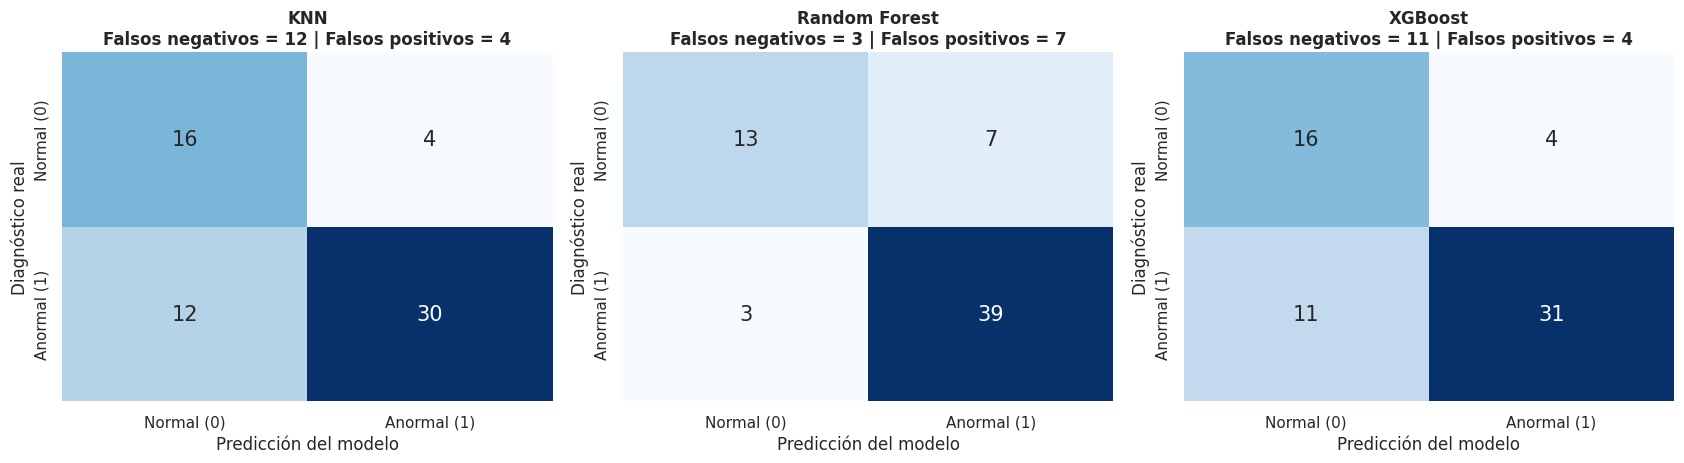

In [ ]:
# Matrices de confusión
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
etiquetas = ['Normal (0)', 'Anormal (1)']
for ax, (n, cm) in zip(axes, cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=etiquetas, yticklabels=etiquetas, annot_kws={'size': 15})
    ax.set_title(f'{n}\nFalsos negativos = {cm[1,0]} | Falsos positivos = {cm[0,1]}', fontweight='bold')
    ax.set_xlabel('Predicción del modelo'); ax.set_ylabel('Diagnóstico real')
plt.tight_layout(); plt.show()

La casilla inferior izquierda de cada matriz contiene los falsos negativos, el error de mayor riesgo clínico: Random Forest tuvo 3, XGBoost 11 y KNN 12. En falsos positivos el orden fue KNN (4), XGBoost (4) y Random Forest (7); es decir, KNN y XGBoost clasificaron correctamente 16 de los 20 pacientes normales y Random Forest 13. El modelo que mejor detecta pacientes anormales es también el que envía más pacientes sanos a estudios adicionales, un intercambio aceptable porque un falso positivo implica una evaluación adicional y un falso negativo puede significar un diagnóstico tardío.

### **11.3 Curvas ROC**

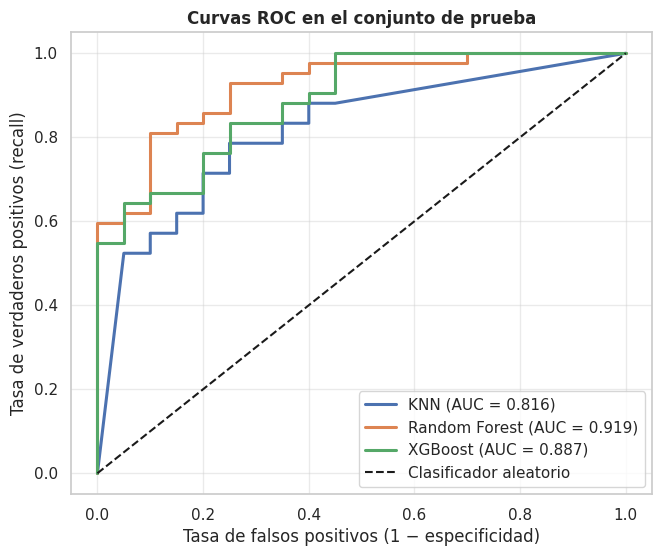

In [ ]:
# Curvas ROC
plt.figure(figsize=(7.5, 6))
aucs = {}
for n, m in mejores.items():
    proba = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    aucs[n] = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, lw=2.2, label=f"{n} (AUC = {aucs[n]:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador aleatorio')
plt.xlabel('Tasa de falsos positivos (1 − especificidad)'); plt.ylabel('Tasa de verdaderos positivos (recall)')
plt.title('Curvas ROC en el conjunto de prueba', fontweight='bold'); plt.legend(loc='lower right'); plt.grid(alpha=.4)
plt.show()

El AUC es de 0.919 en Random Forest, 0.887 en XGBoost y 0.816 en KNN (leyenda del gráfico). Random Forest queda por encima de los demás con baja tasa de falsos positivos (hasta aproximadamente 0.4), mientras que XGBoost alcanza sensibilidad 1.0 antes, con una tasa de falsos positivos cercana a 0.45; la curva de KNN es más escalonada y queda por debajo de las otras dos en casi todo el recorrido. A diferencia de las métricas anteriores, el AUC no depende del umbral de 0.5 (Fawcett, 2006).

### **11.4 Importancia de las variables por permutación**

Se mide cuánto disminuye el ROC AUC en prueba al permutar al azar los valores de una variable (30 repeticiones). Se calcula sobre las seis variables originales y no sobre los componentes del PCA, para poder interpretarla en términos clínicos.

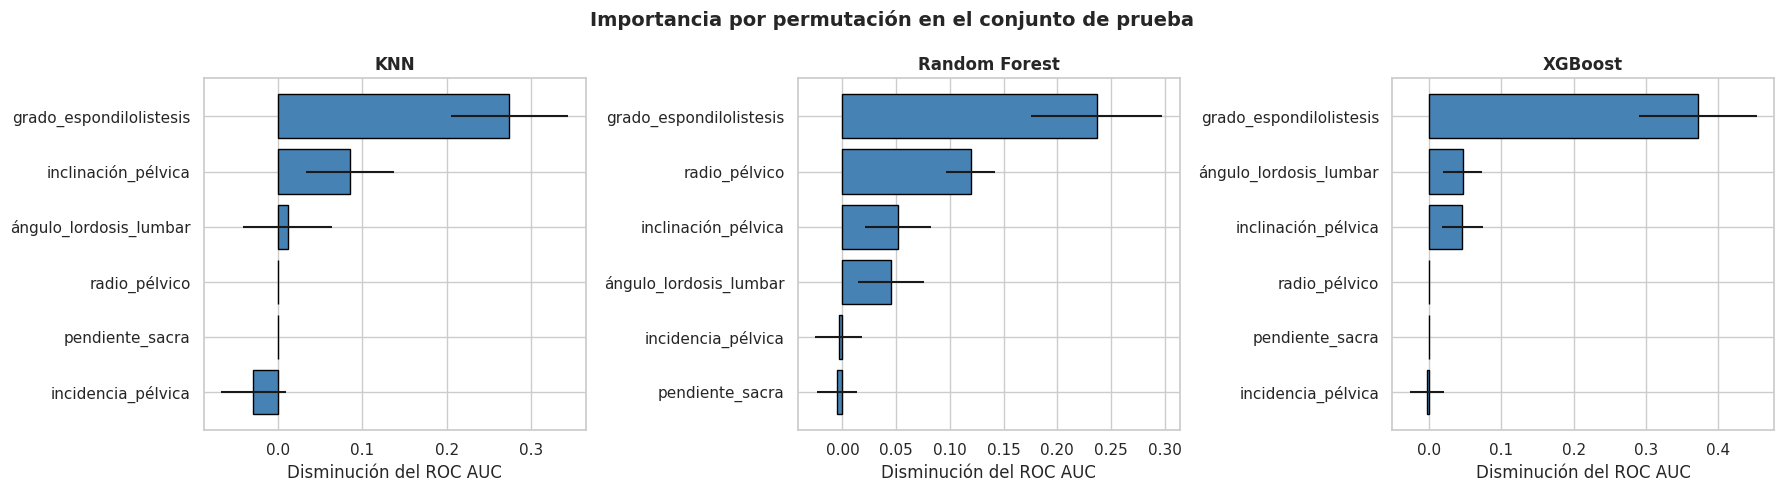

=== IMPORTANCIA POR PERMUTACIÓN (disminución del ROC AUC) ===


,KNN,Random Forest,XGBoost
Variable,,,
grado_espondilolistesis,0.274,0.237,0.372
radio_pélvico,0.000,0.119,0.000
inclinación_pélvica,0.086,0.051,0.046
ángulo_lordosis_lumbar,0.011,0.045,0.046
incidencia_pélvica,-0.029,-0.003,-0.003
pendiente_sacra,0.000,-0.005,0.000


In [ ]:
imp_tab = {}
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (n, m) in zip(axes, mejores.items()):
    pi = permutation_importance(m, X_test, y_test, scoring='roc_auc', n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.DataFrame({'Variable': FEATURES, 'Importancia': pi.importances_mean, 'Desv': pi.importances_std}).sort_values('Importancia')
    imp_tab[n] = imp.set_index('Variable')['Importancia']
    ax.barh(imp['Variable'], imp['Importancia'], xerr=imp['Desv'], color='steelblue', edgecolor='black')
    ax.set_title(n, fontweight='bold'); ax.set_xlabel('Disminución del ROC AUC')
plt.suptitle('Importancia por permutación en el conjunto de prueba', fontsize=14, fontweight='bold'); plt.tight_layout(); plt.show()

print("=== IMPORTANCIA POR PERMUTACIÓN (disminución del ROC AUC) ===")
display(pd.DataFrame(imp_tab).sort_values('Random Forest', ascending=False).round(3))

En los tres modelos la variable más importante es, con diferencia, el grado de espondilolistesis (caída del ROC AUC de 0.274 en KNN, 0.237 en Random Forest y 0.372 en XGBoost, según la tabla), en concordancia con el análisis exploratorio, donde fue la variable más asociada con la clase (r = 0.44). La segunda variable cambia según el modelo: inclinación pélvica en KNN (0.086), radio pélvico en Random Forest (0.119) y lordosis lumbar e inclinación pélvica en XGBoost (ambas ≈ 0.046, prácticamente empatadas). En KNN y XGBoost, el radio pélvico y la pendiente sacra tienen importancia de 0.000, y la incidencia pélvica una importancia cercana a cero en los tres modelos. Una posible explicación, no comprobada aquí, es que parte de la información de la incidencia pélvica la aportan las otras variables pélvicas (PI = PT + SS, sección 4.4). Las barras de error son amplias, por lo que la importancia debe leerse como una tendencia.


### **11.5 Análisis de sensibilidad al tratamiento de los valores negativos de espondilolistesis**

Para medir cuánto depende el desempeño del recorte a cero (sección 3.1), se reentrenan los mismos pipelines (con los hiperparámetros ya seleccionados, sobre la misma partición) bajo cuatro escenarios: (A) recorte a cero, que es el tratamiento base; (B) valores originales sin recortar; (C) valores originales más una variable indicadora de valor negativo; y (D) exclusión de los registros con valor negativo. Previamente se tabula cuántos registros negativos hay en cada clase. Los hiperparámetros no se vuelven a optimizar en cada escenario, por lo que la comparación es aproximada, y con 62 pacientes de prueba las diferencias pequeñas no son concluyentes.

In [ ]:
neg = (gs_original < 0)
print("=== REGISTROS CON ESPONDILOLISTESIS NEGATIVA POR CLASE ===")
display(pd.crosstab(df['clase'].map({0: 'Normal (0)', 1: 'Anormal (1)'}), neg.map({True: 'Negativo', False: 'No negativo'})))
print("\nValores negativos: mínimo =", round(gs_original.min(), 2), "| mediana =", round(gs_original[neg].median(), 2))

idx_tr, idx_te = X_train.index, X_test.index

def construir(escenario):
    X_ = df[FEATURES].copy()
    if escenario in ('B', 'C'):
        X_['grado_espondilolistesis'] = gs_original
    if escenario == 'C':
        X_['espondilolistesis_negativa'] = neg.astype(int)
    tr, te = idx_tr, idx_te
    if escenario == 'D':
        tr, te = idx_tr[~neg.loc[idx_tr].values], idx_te[~neg.loc[idx_te].values]
    return X_.loc[tr], X_.loc[te], df.loc[tr, 'clase'], df.loc[te, 'clase']

nombres_esc = {'A': 'A. Recorte a 0 (base)', 'B': 'B. Valores originales',
               'C': 'C. Originales + indicador de negativo', 'D': 'D. Excluir negativos'}
filas = []
for esc, etiqueta in nombres_esc.items():
    Xtr_, Xte_, ytr_, yte_ = construir(esc)
    for n, m in mejores.items():
        mod = clone(m).fit(Xtr_, ytr_)
        pred, proba = mod.predict(Xte_), mod.predict_proba(Xte_)[:, 1]
        tn_, fp_, fn_, tp_ = confusion_matrix(yte_, pred).ravel()
        filas.append({'Escenario': etiqueta, 'Modelo': n, 'n prueba': len(yte_), 'Recall': recall_score(yte_, pred),
                      'F1-Score': f1_score(yte_, pred), 'ROC AUC': roc_auc_score(yte_, proba), 'FN': fn_, 'FP': fp_})
sens = pd.DataFrame(filas)
print("\n=== DESEMPEÑO EN PRUEBA SEGÚN EL TRATAMIENTO DE LOS NEGATIVOS ===")
display(sens.round(4))
display(sens.pivot(index='Modelo', columns='Escenario', values='ROC AUC').round(3))


=== REGISTROS CON ESPONDILOLISTESIS NEGATIVA POR CLASE ===


grado_espondilolistesis,Negativo,No negativo
clase,,
Anormal (1),19,191
Normal (0),39,61



Valores negativos: mínimo = -11.06 | mediana = -2.42

=== DESEMPEÑO EN PRUEBA SEGÚN EL TRATAMIENTO DE LOS NEGATIVOS ===


,Escenario,Modelo,n prueba,Recall,F1-Score,ROC AUC,FN,FP
0,A. Recorte a 0 (base),KNN,62,0.7143,0.7895,0.8161,12,4
1,A. Recorte a 0 (base),Random Forest,62,0.9286,0.8864,0.9190,3,7
2,A. Recorte a 0 (base),XGBoost,62,0.7381,0.8052,0.8869,11,4
3,B. Valores originales,KNN,62,0.6667,0.7568,0.8042,14,4
4,B. Valores originales,Random Forest,62,0.9286,0.8966,0.9071,3,6
5,B. Valores originales,XGBoost,62,0.7143,0.7792,0.8583,12,5
6,C. Originales + indicador de negativo,KNN,62,0.6429,0.7397,0.8042,15,4
7,C. Originales + indicador de negativo,Random Forest,62,0.8810,0.8506,0.8304,5,8
8,C. Originales + indicador de negativo,XGBoost,62,0.7143,0.7895,0.8714,12,4
9,D. Excluir negativos,KNN,49,0.7895,0.8451,0.8421,8,3


Escenario,A. Recorte a 0 (base),B. Valores originales,C. Originales + indicador de negativo,D. Excluir negativos
Modelo,,,,
KNN,0.816,0.804,0.804,0.842
Random Forest,0.919,0.907,0.830,0.921
XGBoost,0.887,0.858,0.871,0.928


Los registros con espondilolistesis negativa no se reparten por igual entre las clases: 39 de los 100 pacientes Normales (39 %) y 19 de los 210 Anormales (9 %) tienen valor negativo, es decir, dos tercios de los 58 negativos son Normales. Esto indica que el signo no es ruido distribuido al azar, aunque con estos datos no se puede saber si refleja un hallazgo clínico real o un artefacto de medición.

Respecto al efecto sobre los modelos (conjunto de prueba de 62 pacientes), al no recortar los valores (escenario B) Random Forest mantiene el mismo recall que con el recorte a cero (0.9286, 3 falsos negativos), con un F1 ligeramente mayor (0.8966 frente a 0.8864) y un ROC AUC algo menor (0.907 frente a 0.919), mientras que KNN y XGBoost empeoran levemente (F1 de 0.789 a 0.757 y de 0.805 a 0.779; ROC AUC de 0.816 a 0.804 y de 0.887 a 0.858). Son cambios de uno o dos pacientes, por lo que no son concluyentes, pero el recorte a cero no parece haber inflado el desempeño. Agregar el indicador de negativo (escenario C) no mejora a ningún modelo y Random Forest baja a un recall de 0.881 y un ROC AUC de 0.830. Al excluir los negativos (escenario D) el conjunto de prueba queda en 49 pacientes (se excluyen 9 de los 20 Normales y 4 de los 42 Anormales), de modo que sus métricas no son directamente comparables con las de los otros escenarios. Random Forest conserva el mayor recall en los cuatro escenarios, pero su ventaja en ROC AUC solo se mantiene en A y B; en C y D, XGBoost lo supera.

En conjunto, la elección de Random Forest por su sensibilidad es estable frente al tratamiento de los negativos, pero el análisis no sustituye la validación clínica: no indica cuál es el tratamiento correcto, solo que las conclusiones principales no cambian de forma drástica bajo las alternativas probadas. Los hiperparámetros no se reoptimizaron en cada escenario.

---
## **12. Conclusiones, Decisiones y Recomendaciones**

### **12.1 Selección del modelo**

Para tomar la decisión se construyó un puntaje ponderado que refleja el criterio clínico y de estabilidad: 50 % recall en prueba (capacidad de detectar pacientes anormales), 30 % F1-Score en validación cruzada (estimación más estable por usar toda la muestra de entrenamiento) y 20 % ROC AUC en prueba (capacidad global de discriminación).

In [ ]:
rank = res_test.copy()
rank['FN']        = [int(cms[n][1, 0]) for n in rank.index]
rank['FP']        = [int(cms[n][0, 1]) for n in rank.index]
rank['F1 CV']     = [busquedas[n].cv_results_['mean_test_f1'][busquedas[n].best_index_] for n in rank.index]
rank['F1 CV (±)'] = [busquedas[n].cv_results_['std_test_f1'][busquedas[n].best_index_] for n in rank.index]
rank['Puntaje']   = 0.5*rank['Recall'] + 0.3*rank['F1 CV'] + 0.2*rank['ROC AUC']
display(rank.round(4))

elegido = rank['Puntaje'].idxmax()

,Accuracy,Precision,Recall,F1-Score,F2-Score,ROC AUC,FN,FP,F1 CV,F1 CV (±),Puntaje
KNN,0.7419,0.8824,0.7143,0.7895,0.7426,0.8161,12,4,0.8464,0.0450,0.7743
Random Forest,0.8387,0.8478,0.9286,0.8864,0.9112,0.9190,3,7,0.8700,0.0335,0.9091
XGBoost,0.7581,0.8857,0.7381,0.8052,0.7635,0.8869,11,4,0.8745,0.0614,0.8088


Según el puntaje ponderado de la tabla, el modelo seleccionado es Random Forest (0.9091, frente a 0.8088 de XGBoost y 0.7743 de KNN), con 300 árboles, profundidad máxima de 10, 1 muestra mínima por hoja y PCA de 4 componentes (sección 8). En prueba obtuvo un recall de 0.9286 (3 falsos negativos y 7 falsos positivos), un F1 de 0.8864 y un ROC AUC de 0.9190, y en validación cruzada un F1 de 0.8700 (± 0.0335). La mitad del puntaje es el recall en prueba, métrica en la que Random Forest destaca; la decisión es coherente con la prioridad clínica de minimizar falsos negativos.

### **12.2 Conclusiones**

Entre los tres modelos evaluados, Random Forest se consolidó como la opción más sólida, ya que alcanzó el mejor desempeño tanto en el conjunto de prueba (un recall de 0.9286, un F1-Score de 0.8864 y un ROC AUC de 0.9190) como en la validación cruzada repetida (recall de 0.846 y F1 de 0.862). No obstante, esta superioridad debe matizarse: XGBoost lo superó ligeramente en el F1 de la validación simple (0.8745 frente a 0.8700), y las diferencias entre los F1 medios de la validación repetida (que oscilan entre 0.823 y 0.862) resultan menores que la variabilidad que cada modelo presenta entre particiones (aproximadamente 0.045 a 0.047). Por consiguiente, aunque la elección de Random Forest es razonable y coherente con la prioridad clínica de minimizar los falsos negativos, no puede afirmarse que exista una superioridad estadísticamente demostrada.

En cuanto a la robustez de las estimaciones, el tamaño reducido de la muestra de prueba (62 pacientes) introduce una variabilidad considerable, como refleja el intervalo de Wilson del recall de Random Forest (0.810 a 0.975), y la validación simple resultó más optimista que la repetida (el F1 de XGBoost descendió de 0.875 a 0.828).

Finalmente, los resultados dependen del tratamiento aplicado a los valores negativos del grado de espondilolistesis (58 registros llevados a cero, sección 3.1), variable que resultó la más importante en los tres modelos. El análisis de sensibilidad (sección 11.5) muestra que, al no recortarlos, Random Forest conserva su recall (0.9286) y que KNN y XGBoost empeoran levemente, por lo que la conclusión sobre el mejor modelo no cambia de forma drástica; sin embargo, el criterio no ha sido validado por un especialista, y el desempeño reportado debe interpretarse como condicionado a esa decisión. En síntesis, la contribución principal de este trabajo es de naturaleza metodológica: se construyó un pipeline reproducible y libre de fuga de información, se aplicó una validación más rigurosa que una partición simple y se profundizó en la interpretación de los modelos.


### **12.3 Limitaciones**

- Tamaño de la muestra de 310 pacientes y solo 62 en la prueba; las métricas tienen alta variabilidad y dependen de una sola partición (`random_state = 42`).
- 58 de los 310 registros tenían espondilolistesis negativa y se llevaron a cero. El significado clínico de esos valores no está documentado en el conjunto de datos (podrían ser retrolistesis reales (Shimizu et al., 2023), una convención de signo o ruido de medición), por lo que el recorte pudo eliminar información. Además, el signo no se reparte al azar entre clases (39 % de los Normales y 9 % de los Anormales tienen valor negativo). El criterio no ha sido validado por un especialista, y las estadísticas descriptivas, la importancia de variables y las métricas dependen de él. El análisis de sensibilidad (sección 11.5) no reoptimizó los hiperparámetros en cada escenario.
- El SMOTE se aplica solo en entrenamiento, pero sus ejemplos son interpolaciones y no pacientes reales.


### **12.4 Recomendaciones y próximos pasos**

- Validar con un especialista en ortopedia o columna el significado de los valores negativos de espondilolistesis y definir con él el tratamiento adecuado (conservarlos como retrolistesis, tratarlos como error de medición o excluirlos).
- Ampliar el análisis de sensibilidad de la sección 11.5 reoptimizando los hiperparámetros en cada escenario, con validación cruzada repetida y comparando también la importancia de variables.
- Explorar ingeniería de características (razones y productos entre variables, transformación logarítmica de la espondilolistesis) dentro del pipeline.
- Validación cruzada anidada y varias semillas de partición (Cawley & Talbot, 2010), más datos y validación externa en otras instituciones.
- El modelo debe usarse como apoyo al cribado, no como sustituto del criterio del especialista.

---
## **13. Referencias**

Aggarwal, C. C. (2017). *Outlier Analysis* (2.ª ed.). Springer. https://sadbhavnapublications.org/research-enrichment-material/2-Statistical-Books/Outlier-Analysis.pdf

Aranda Grijalba, C., & Pérez López, L. M. (s. f.). *Mediciones radiográficas habituales en COT (columna, cadera, miembros inferiores y pie)* (Capítulo 25). Althaia Xarxa Assistencial de Manresa. https://unitia.secot.es/web/manual_residente/CAPITULO%2025.pdf

Berthonnaud, E., Dimnet, J., Roussouly, P., & Labelle, H. (2005). Analysis of the sagittal balance of the spine and pelvis using shape and orientation parameters. *Journal of Spinal Disorders & Techniques, 18*(1), 40–47. https://pubmed.ncbi.nlm.nih.gov/15687851/

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://link.springer.com/article/10.1023/A:1010933404324

Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research, 11*, 2079–2107. https://www.jmlr.org/papers/volume11/cawley10a/cawley10a.pdf

Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://www.researchgate.net/publication/220543125_SMOTE_Synthetic_Minority_Over-sampling_Technique

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. En *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 785–794). ACM. https://www.kdd.org/kdd2016/papers/files/rfp0697-chenAemb.pdf

Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory, 13*(1), 21–27. https://isl.stanford.edu/~cover/papers/transIT/0021cove.pdf

Dua, D., & Graff, C. (2019). *UCI Machine Learning Repository: Vertebral Column Data Set*. University of California, Irvine. https://archive.ics.uci.edu/ml

Fawcett, T. (2006). An introduction to ROC analysis. *Pattern Recognition Letters, 27*(8), 861–874. https://www.researchgate.net/publication/222511520_Introduction_to_ROC_analysis

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction* (2.ª ed.). Springer. https://esl.hohoweiya.xyz/book/The%20Elements%20of%20Statistical%20Learning.pdf

Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://royalsocietypublishing.org/rsta/article/374/2065/20150202/115142/Principal-component-analysis-a-review-and-recent

Le Huec, J. C., Aunoble, S., Philippe, L., & Nicolas, P. (2011). Pelvic parameters: Origin and significance. *European Spine Journal, 20*(Suppl 5), 564–571. https://fasterspine.org/upload/bibliotheque/bibliographie/02_pelvic_parameters_origin_significance.pdf

Lemaître, G., Nogueira, F., & Aridas, C. K. (2017). Imbalanced-learn: A Python toolbox to tackle the curse of imbalanced datasets in machine learning. *Journal of Machine Learning Research, 18*(17), 1–5. https://www.jmlr.org/papers/volume18/16-365/16-365.pdf

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://www.jmlr.org/papers/volume12/pedregosa11a/pedregosa11a.pdf

Romero, I., & Romano, O. A. (s. f.). Deformidad espinal del adulto (Capítulo 73, pp. 897–909). En O. A. Romano & C. A. Fernández (Coords.), *Lo esencial en ortopedia y traumatología*. Facultad de Ciencias Médicas, Universidad Nacional de La Plata. https://sedici.unlp.edu.ar/bitstream/handle/10915/178415/Documento_completo.pdf-PDFA.pdf

Shimizu, M., Kobayashi, T., Chiba, H., Senoo, I., Mizutani, K., & Sasai, K. (2023). Physical and radiographic features of degenerative retrolisthesis in Japanese female volunteers: an observational cohort study. *Scientific Reports, 13*, 396. https://doi.org/10.1038/s41598-023-27702-4

Tabares Neyra, H. I., Fleites Marrero, E. E., Tabares Sáez, H., & Morales Seife, R. (2020). Influencia del balance sagital sobre los cambios degenerativos de la columna vertebral (I). *Revista Cubana de Ortopedia y Traumatología, 34*(2), e185. https://revortopedia.sld.cu/index.php/revortopedia/article/view/185

Topolniak, R., Astur, N., Santos, W. Z., Mendonça, R. G. M., Gotfryd, A. O., Caffaro, M. F. S., & Meves, R. (2022). Impact of the sitting position on lumbar lordosis and its correlation with pelvic parameters. *Coluna/Columna, 21*(4), e262613. https://www.scielo.br/j/coluna/a/xRtGTdp4YH3jdB6gtWJyc7R/?format=pdf&lang=en

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212 https://www.jstor.org/stable/2276774?seq=1